# SAM2 vs UltraSAM2 — Center of Mass Analysis

Computes the center of mass (CoM) of predicted nerve masks for all frames and all models:
- **SAM2** and **UltraSAM2** on raw input
- **SAM2 (denoised)** and **UltraSAM2 (denoised)** on Speckle2Self output
- **GT** (only annotated frames)

Per-patient figure layout:
- **Left** — 2D trajectory: spatial path of CoM across all frames  
- **Right top** — x(t): horizontal position over frame index  
- **Right bottom** — y(t): vertical position over frame index  

Dashed vertical lines mark boundaries between different video clips within the same patient.

In [136]:
import os
import re
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from IPython.display import display as ipy_display, Image as IPyImage

In [137]:
# ── Paths ─────────────────────────────────────────────────────────────────────
GT_ROOT       = r"D:\annotated_pn"
SAM2_RAW_ROOT = r"D:\sam2-results"
SAM2_DN_ROOT  = r"D:\sam2-results\denoised"
US2_RAW_ROOT  = r"D:\ultrasam2-results\inference1"
US2_DN_ROOT   = r"D:\ultrasam2-results\inference1_dn"
RAW_SRC_ROOT  = r"D:\dissertation-results\cropped_pngs3"

OUT_DIR = os.getcwd()

PATIENTS = {
    "Almeida": "AlmeidaDenoised2_nerve",
    "Borges":  "BorgesDenoised2_nerve",
    "Brito":   "BritoDenoised2_nerve",
}
LABEL_MAP = {"Almeida": "Patient 1", "Borges": "Patient 2", "Brito": "Patient 3"}

# (display label, cx_col, cy_col, color, linestyle, linewidth)
MODELS = [
    ("SAM2",                 "s2_raw_cx",  "s2_raw_cy",  "#1f77b4", "-",  1.8),
    ("UltraSAM2",            "us2_raw_cx", "us2_raw_cy", "#ff7f0e", "-",  1.8),
    ("SAM2 (denoised)",      "s2_dn_cx",   "s2_dn_cy",   "#17becf", "--", 1.3),
    ("UltraSAM2 (denoised)", "us2_dn_cx",  "us2_dn_cy",  "#d62728", "--", 1.3),
]

In [138]:
# ── Helpers ───────────────────────────────────────────────────────────────────
def frame_key_from_gt(fname: str) -> str:
    s = re.sub(r'^Label_\d+_', '', fname)
    return s.replace('_denoised.png', '').replace('.png', '')


def index_masks(mask_dir: str, suffixes: list) -> dict:
    if not os.path.exists(mask_dir):
        return {}
    idx = {}
    for f in os.listdir(mask_dir):
        if not f.endswith('.png'):
            continue
        key = f
        for suf in suffixes:
            if key.endswith(suf):
                key = key[:-len(suf)]
                break
        idx[key] = os.path.join(mask_dir, f)
    return idx


def sort_key(frame_key: str) -> tuple:
    """Sort by (video_number, frame_number) extracted from filename."""
    nums = tuple(int(x) for x in re.findall(r'\d+', frame_key))
    return nums if nums else (0,)


def compute_com(path) -> tuple:
    """Returns (cx, cy) in pixels. cx = col (right+), cy = row (down+)."""
    if path is None:
        return float('nan'), float('nan')
    try:
        if pd.isna(path):
            return float('nan'), float('nan')
    except (TypeError, ValueError):
        pass
    try:
        mask = np.array(Image.open(path).convert('L')) > 0
    except Exception:
        return float('nan'), float('nan')
    pts = np.argwhere(mask)  # [[row, col], ...]
    if len(pts) == 0:
        return float('nan'), float('nan')
    return float(pts[:, 1].mean()), float(pts[:, 0].mean())  # (cx, cy)

In [139]:
# ── Build frame table (all frames in temporal order) ──────────────────────────
records = []

for patient, gt_folder in PATIENTS.items():
    src_dir  = os.path.join(RAW_SRC_ROOT, patient, "cross-section")
    all_keys = sorted(
        [f[:-4] for f in os.listdir(src_dir) if f.endswith('.png')],
        key=sort_key
    )

    gt_dir   = os.path.join(GT_ROOT, gt_folder)
    gt_index = {
        frame_key_from_gt(f): os.path.join(gt_dir, f)
        for f in os.listdir(gt_dir) if f.endswith('.png')
    }

    s2_raw  = index_masks(os.path.join(SAM2_RAW_ROOT, patient, "masks"),
                           ['_mask.png'])
    s2_dn   = index_masks(os.path.join(SAM2_DN_ROOT, patient, "masks"),
                           ['_denoised_mask.png', '_mask.png'])
    us2_raw = index_masks(os.path.join(US2_RAW_ROOT, patient, "masks"),
                           ['_mask.png'])
    us2_dn  = index_masks(os.path.join(US2_DN_ROOT, patient.lower(), "masks"),
                           ['_denoised_mask.png', '_mask.png'])

    for fk in all_keys:
        records.append({
            "patient":      patient,
            "frame_key":    fk,
            "gt_path":      gt_index.get(fk),
            "s2_raw_mask":  s2_raw.get(fk),
            "s2_dn_mask":   s2_dn.get(fk),
            "us2_raw_mask": us2_raw.get(fk),
            "us2_dn_mask":  us2_dn.get(fk),
        })

df = pd.DataFrame(records)
print(f"Total frames: {len(df)}")
print(df.groupby('patient').size().rename('frames'))
print(f"\nAnnotated frames: {df['gt_path'].notna().sum()}")

Total frames: 767
patient
Almeida    249
Borges     269
Brito      249
Name: frames, dtype: int64

Annotated frames: 134


In [140]:
# ── Compute center of mass for every model and every frame ────────────────────
print("Computing centers of mass...")

for prefix, mask_col in [
    ("s2_raw",  "s2_raw_mask"),
    ("us2_raw", "us2_raw_mask"),
    ("s2_dn",   "s2_dn_mask"),
    ("us2_dn",  "us2_dn_mask"),
    ("gt",      "gt_path"),
]:
    coms = df[mask_col].map(compute_com)
    df[f"{prefix}_cx"] = coms.map(lambda t: t[0])
    df[f"{prefix}_cy"] = coms.map(lambda t: t[1])
    n_valid = df[f"{prefix}_cx"].notna().sum()
    print(f"  {prefix:10s}: {n_valid} / {len(df)} valid")

print("\nSample (first annotated frame per patient):")
cols = ['patient', 'frame_key', 's2_raw_cx', 's2_raw_cy', 'us2_raw_cx', 'us2_raw_cy', 'gt_cx', 'gt_cy']
print(df.dropna(subset=['gt_cx']).groupby('patient').first()[cols[2:]].to_string())

Computing centers of mass...
  s2_raw    : 767 / 767 valid
  us2_raw   : 767 / 767 valid
  s2_dn     : 767 / 767 valid
  us2_dn    : 767 / 767 valid
  gt        : 134 / 767 valid

Sample (first annotated frame per patient):
          s2_raw_cx   s2_raw_cy  us2_raw_cx  us2_raw_cy       gt_cx       gt_cy
patient                                                                        
Almeida  312.055201  110.915602  310.244564  114.657111  310.501479  111.718639
Borges   302.892685  128.496472  304.800531  128.535347  302.041612  130.314261
Brito    271.006716  158.654301  262.932494  155.908179  278.122943  165.259598


In [141]:
# ── Plotting helper: one figure per video, displayed inline ───────────────────
from io import BytesIO

# How many times the data range to show as context around it (1 = tight, 5 = lots of space)
PADDING_FACTOR = 1

def plot_patient_videos(patient):
    pdf = df[df['patient'] == patient].reset_index(drop=True)
    label = LABEL_MAP[patient]

    # compute CoM range across ALL videos for this patient (consistent axes)
    all_cx = pd.concat([pdf[col] for _, col, _, _, _, _ in MODELS]).dropna()
    all_cy = pd.concat([pdf[col] for _, _, col, _, _, _ in MODELS]).dropna()

    cx_min, cx_max = all_cx.min(), all_cx.max()
    cy_min, cy_max = all_cy.min(), all_cy.max()
    cx_range = max(cx_max - cx_min, 1)
    cy_range = max(cy_max - cy_min, 1)

    x_lo = cx_min - cx_range * PADDING_FACTOR / 2
    x_hi = cx_max + cx_range * PADDING_FACTOR / 2
    y_lo = cy_min - cy_range * PADDING_FACTOR / 2
    y_hi = cy_max + cy_range * PADDING_FACTOR / 2

    print(f"{patient}: cx=[{cx_min:.0f},{cx_max:.0f}] cy=[{cy_min:.0f},{cy_max:.0f}]")
    print(f"  axis window: x=[{x_lo:.0f},{x_hi:.0f}]  y=[{y_lo:.0f},{y_hi:.0f}]")

    # extract video id = everything before _frame_NNN
    pdf['_vid_id'] = pdf['frame_key'].apply(lambda fk: re.sub(r'_frame_\d+$', '', fk))
    vid_ids = pdf['_vid_id'].unique()

    for vid_id in vid_ids:
        vdf = pdf[pdf['_vid_id'] == vid_id].reset_index(drop=True)
        idx = np.arange(len(vdf))

        fig, (ax_x, ax_y) = plt.subplots(2, 1, figsize=(12, 6),
                                          sharex=True,
                                          gridspec_kw={'hspace': 0.35})
        fig.suptitle(f"{label} — {vid_id}", fontsize=13, fontweight='bold')

        for mlabel, cx_col, cy_col, color, ls, lw in MODELS:
            cx = vdf[cx_col].values
            cy = vdf[cy_col].values
            valid = ~np.isnan(cx) & ~np.isnan(cy)
            if not valid.any():
                continue
            ax_x.plot(idx[valid], cx[valid], color=color, ls=ls, lw=lw, alpha=0.85, label=mlabel)
            ax_y.plot(idx[valid], cy[valid], color=color, ls=ls, lw=lw, alpha=0.85, label=mlabel)

        gt_valid = ~np.isnan(vdf['gt_cx'].values) & ~np.isnan(vdf['gt_cy'].values)
        if gt_valid.any():
            ax_x.scatter(idx[gt_valid], vdf['gt_cx'].values[gt_valid],
                         color='#2ca02c', marker='x', s=30, zorder=5, label='GT')
            ax_y.scatter(idx[gt_valid], vdf['gt_cy'].values[gt_valid],
                         color='#2ca02c', marker='x', s=30, zorder=5, label='GT')

        ax_x.set_ylim(x_lo, x_hi)
        ax_y.set_ylim(y_hi, y_lo)    # image coordinate convention: 0 at top

        ax_x.set_ylabel("x (px)", fontsize=11)
        ax_x.set_title("Horizontal position", fontsize=11)
        ax_x.legend(fontsize=9, loc='best')

        ax_y.set_xlabel("Frame index (within video)", fontsize=11)
        ax_y.set_ylabel("y (px)", fontsize=11)
        ax_y.set_title("Vertical position", fontsize=11)
        ax_y.legend(fontsize=9, loc='best')

        plt.tight_layout(rect=[0, 0, 1, 0.93])
        buf = BytesIO()
        fig.savefig(buf, format='png', dpi=120, bbox_inches='tight')
        buf.seek(0)
        ipy_display(IPyImage(data=buf.read()))
        plt.close(fig)

Almeida: cx=[281,379] cy=[111,145]
  axis window: x=[231,428]  y=[94,162]


C:\Users\João\AppData\Local\Temp\ipykernel_25428\1639915513.py:69: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.93])


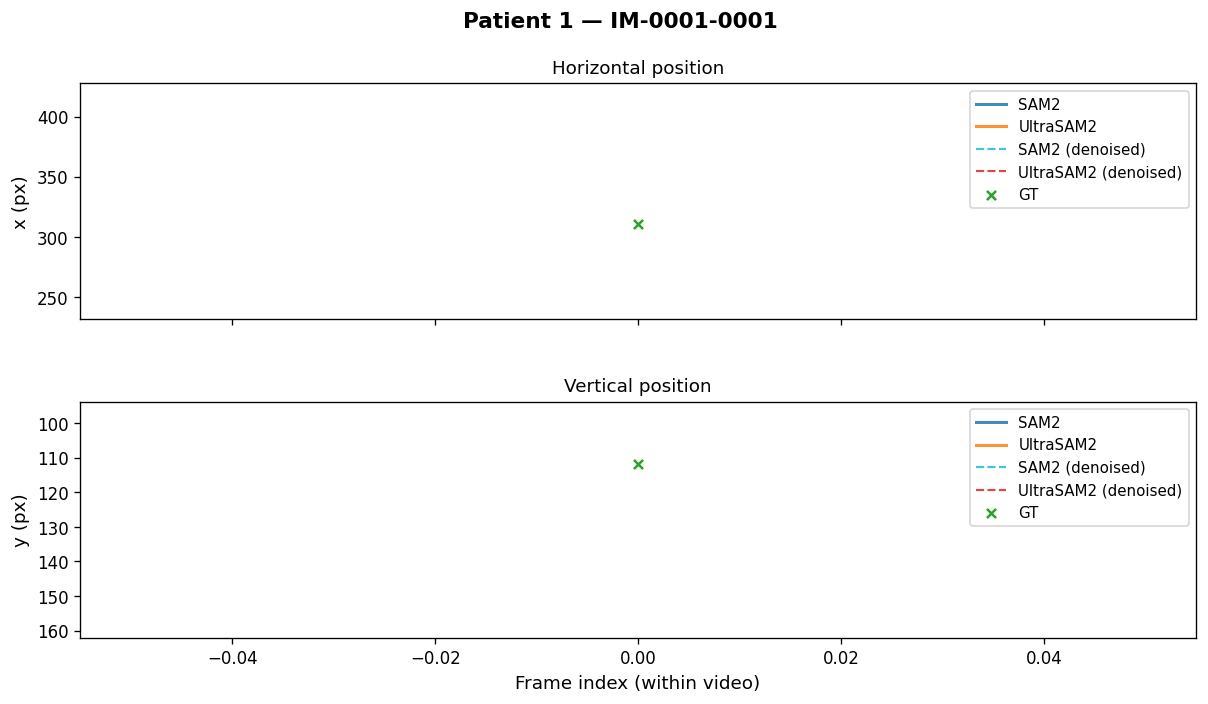

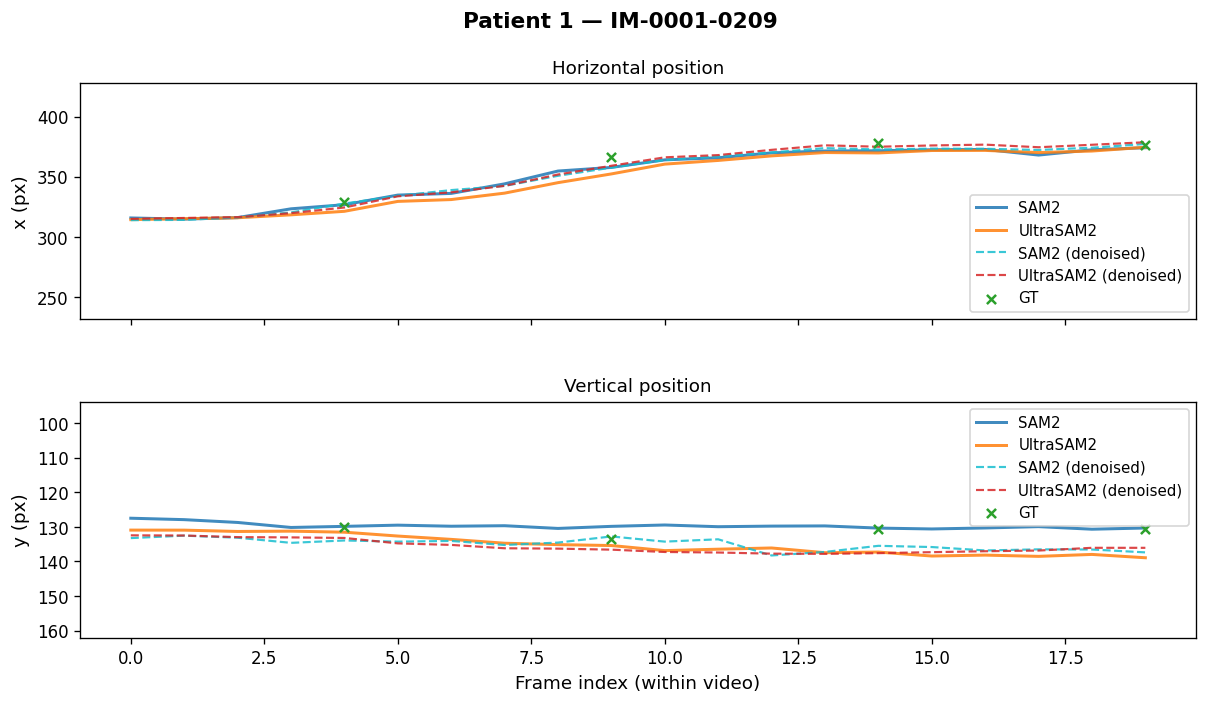

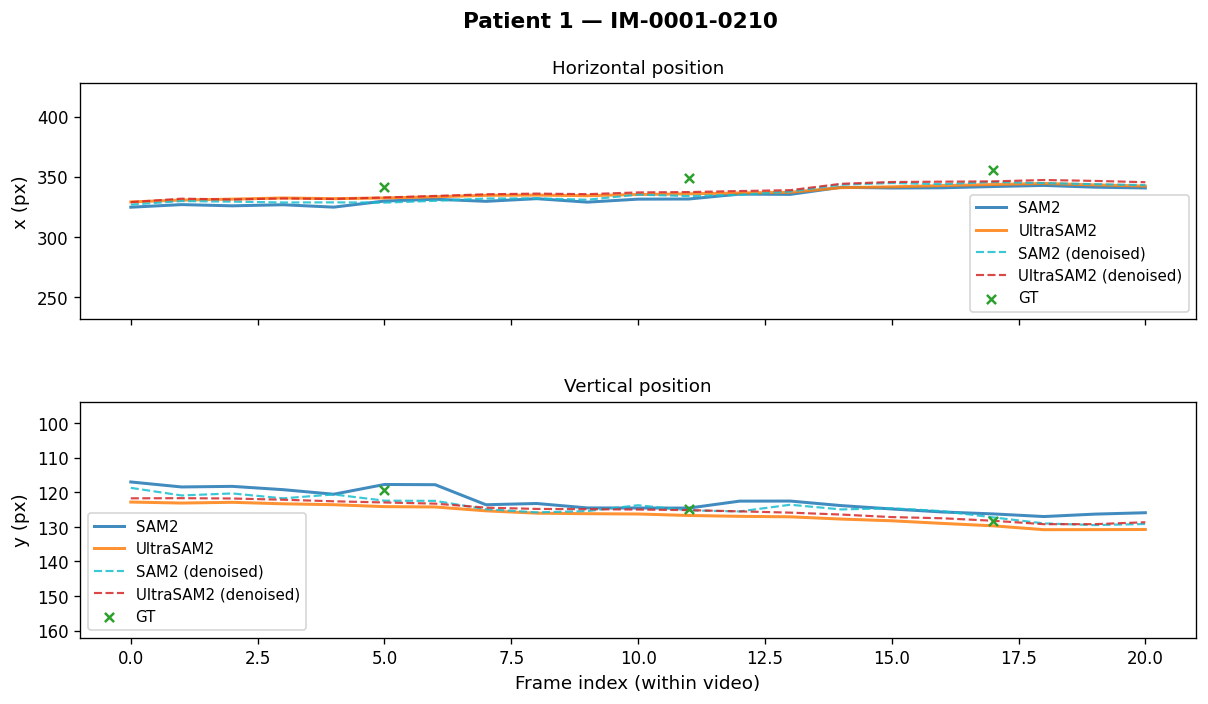

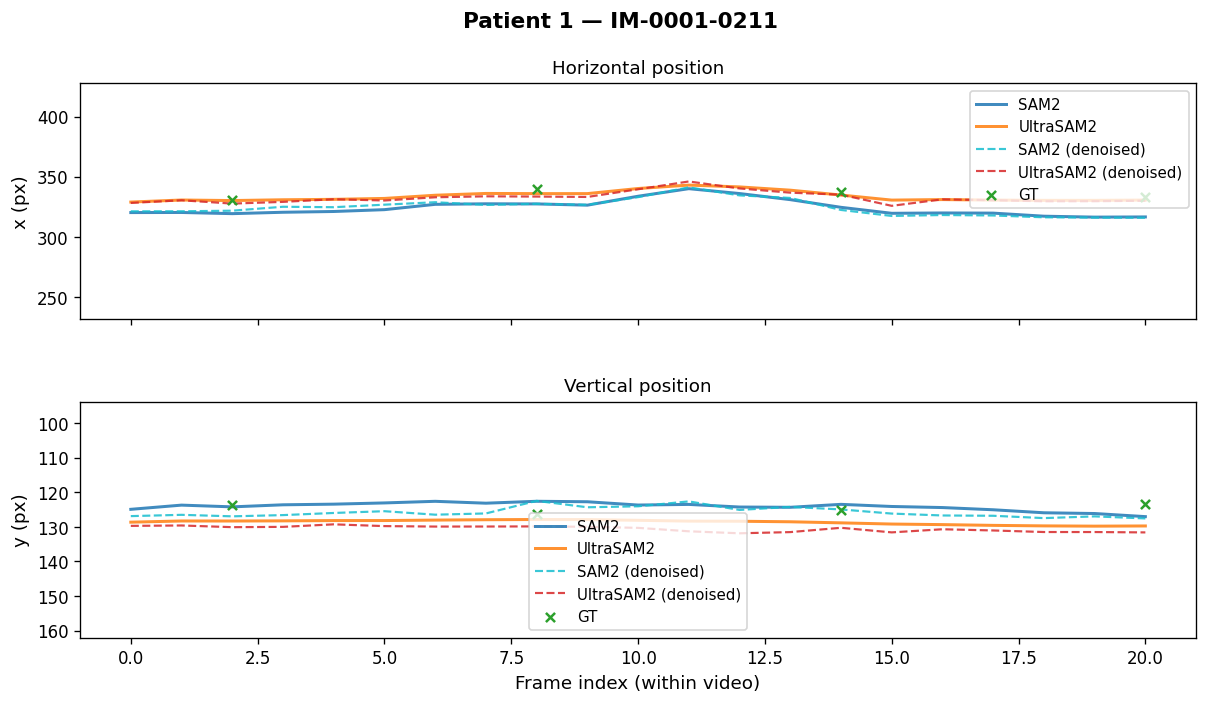

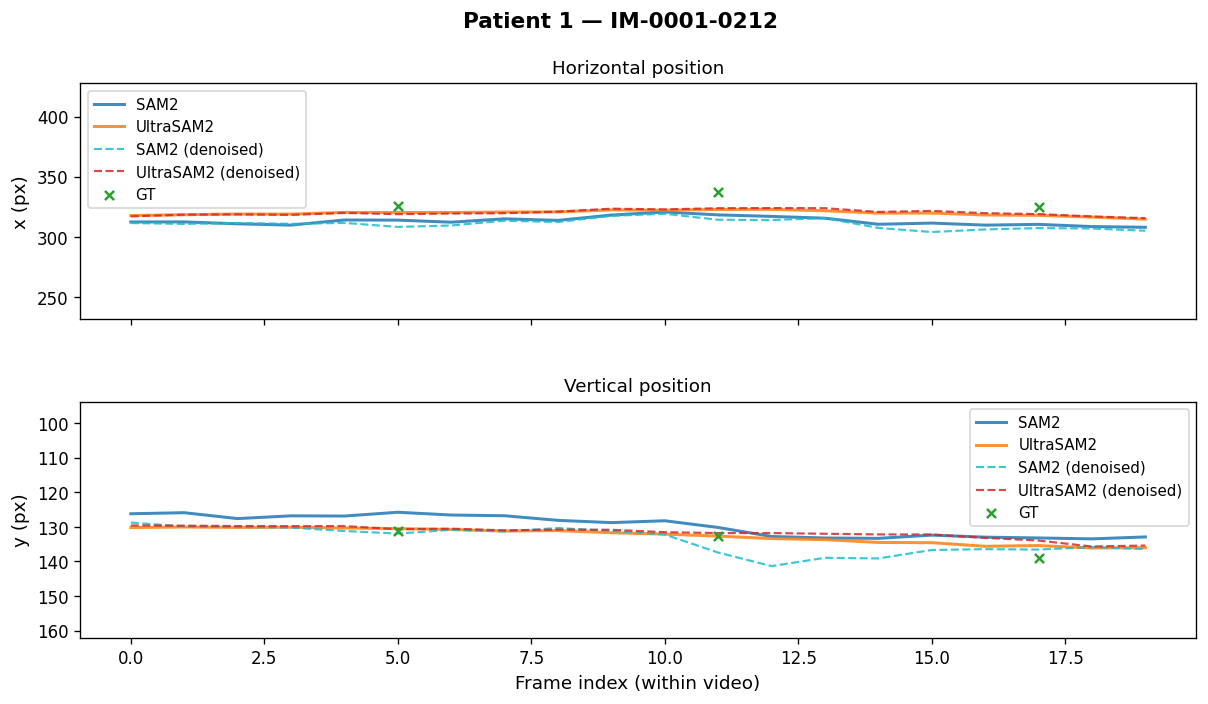

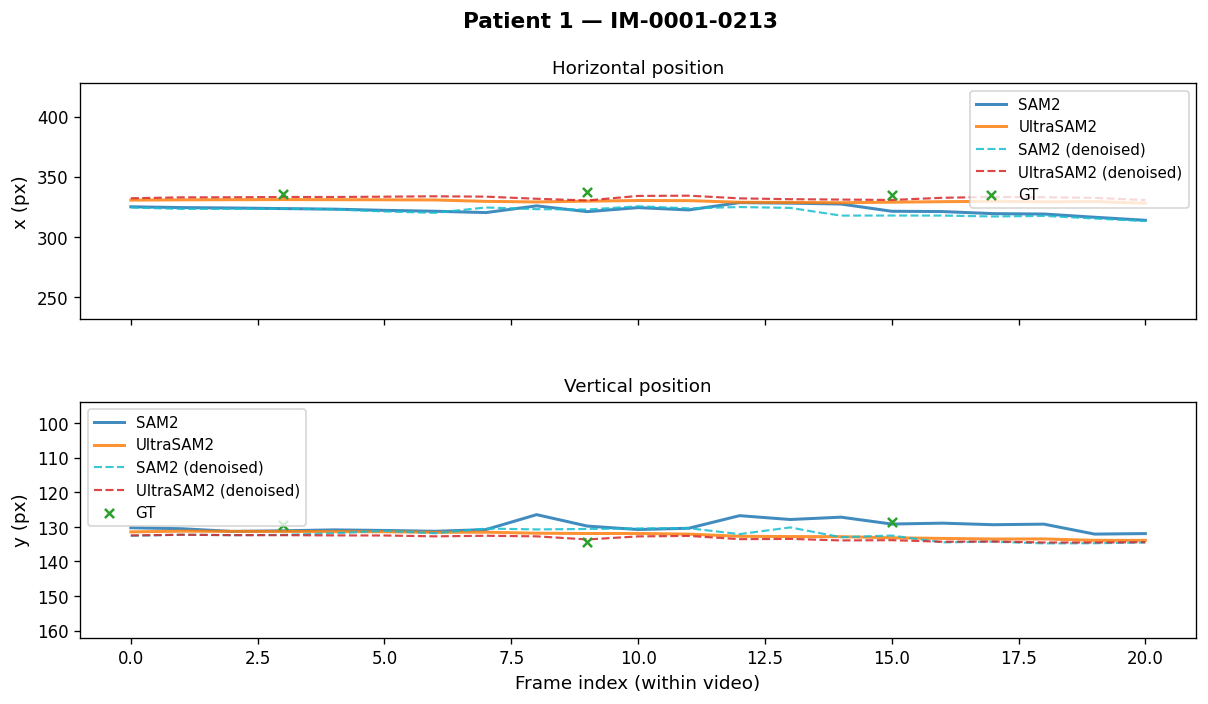

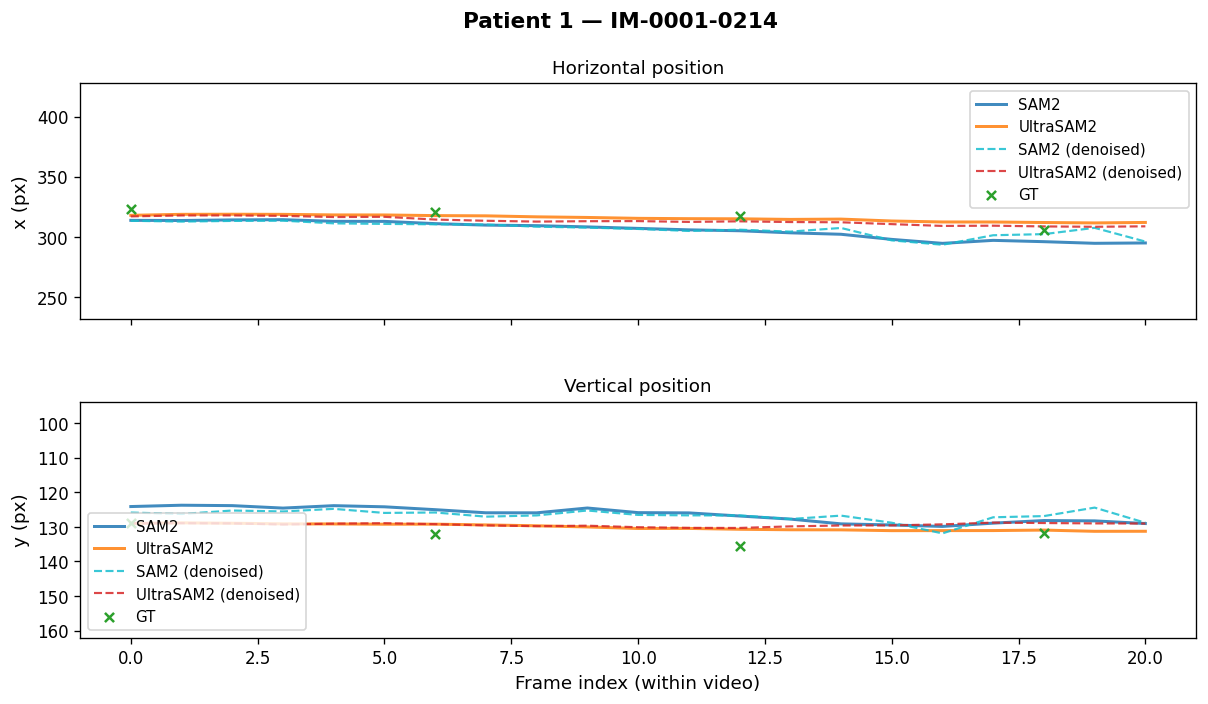

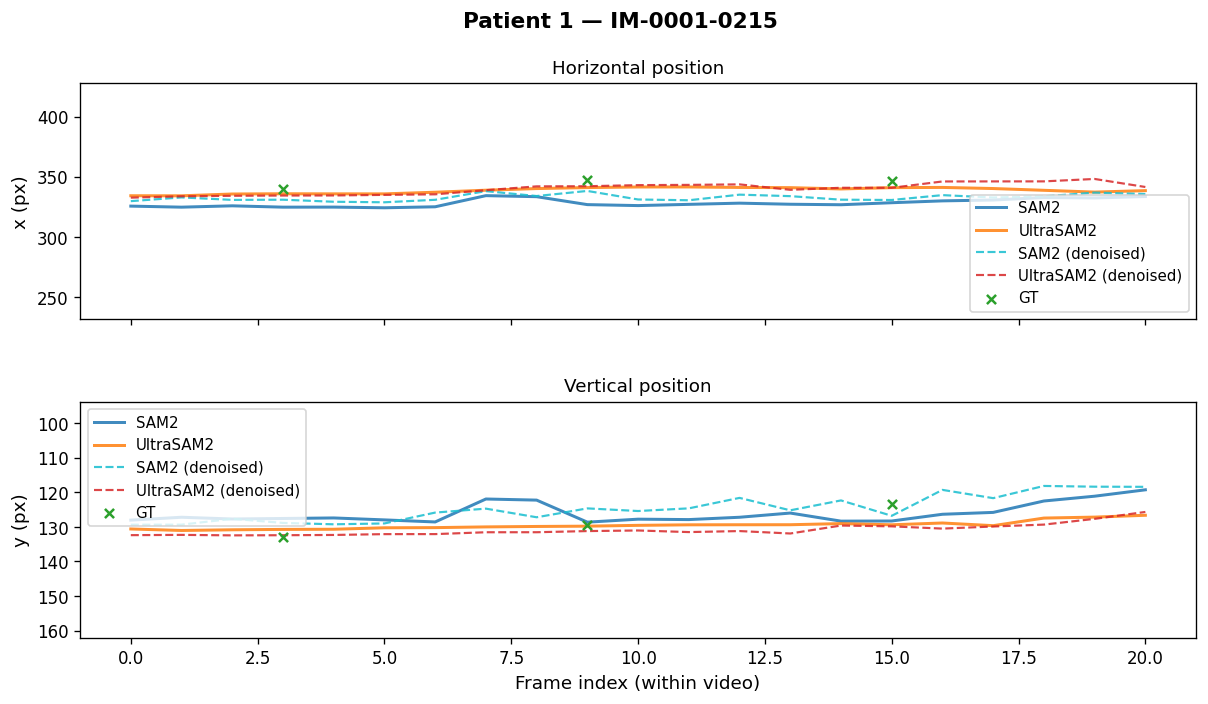

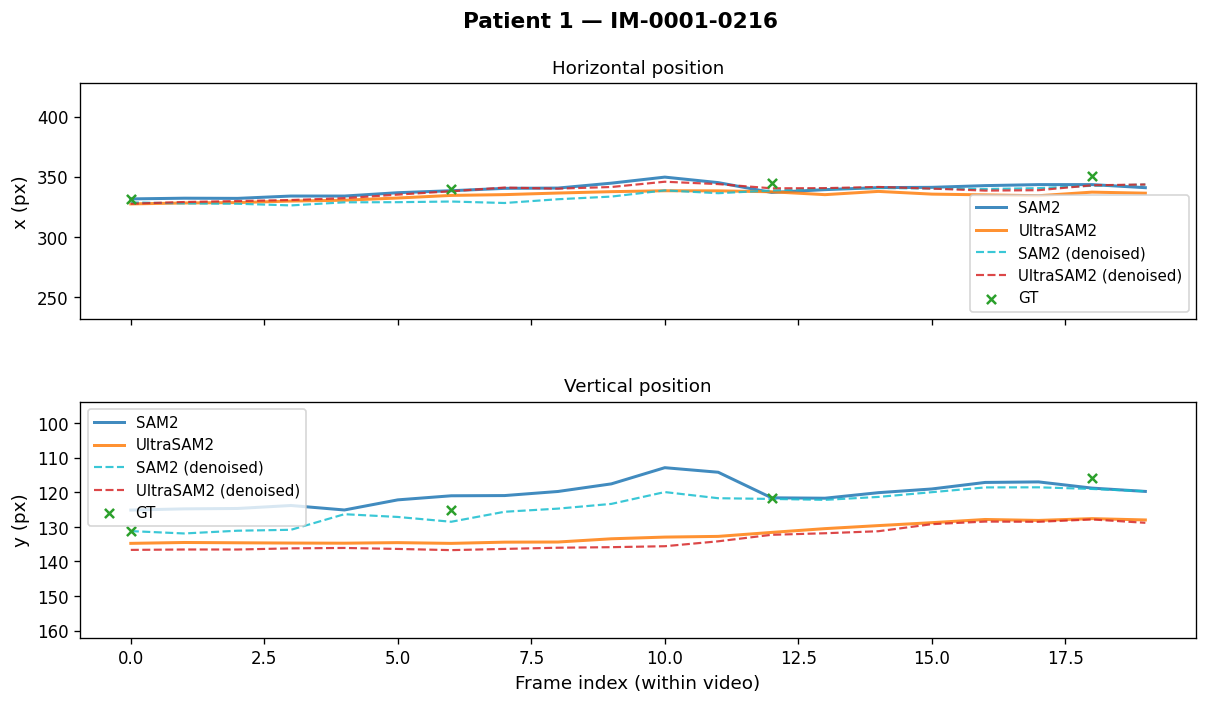

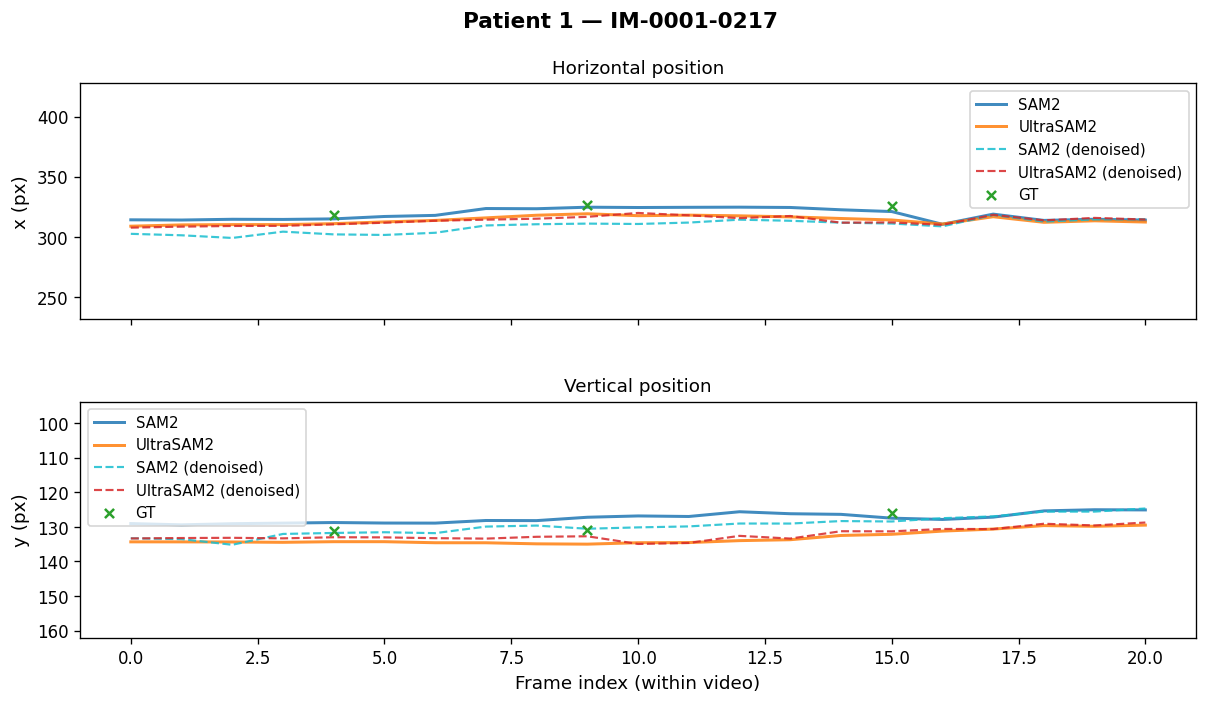

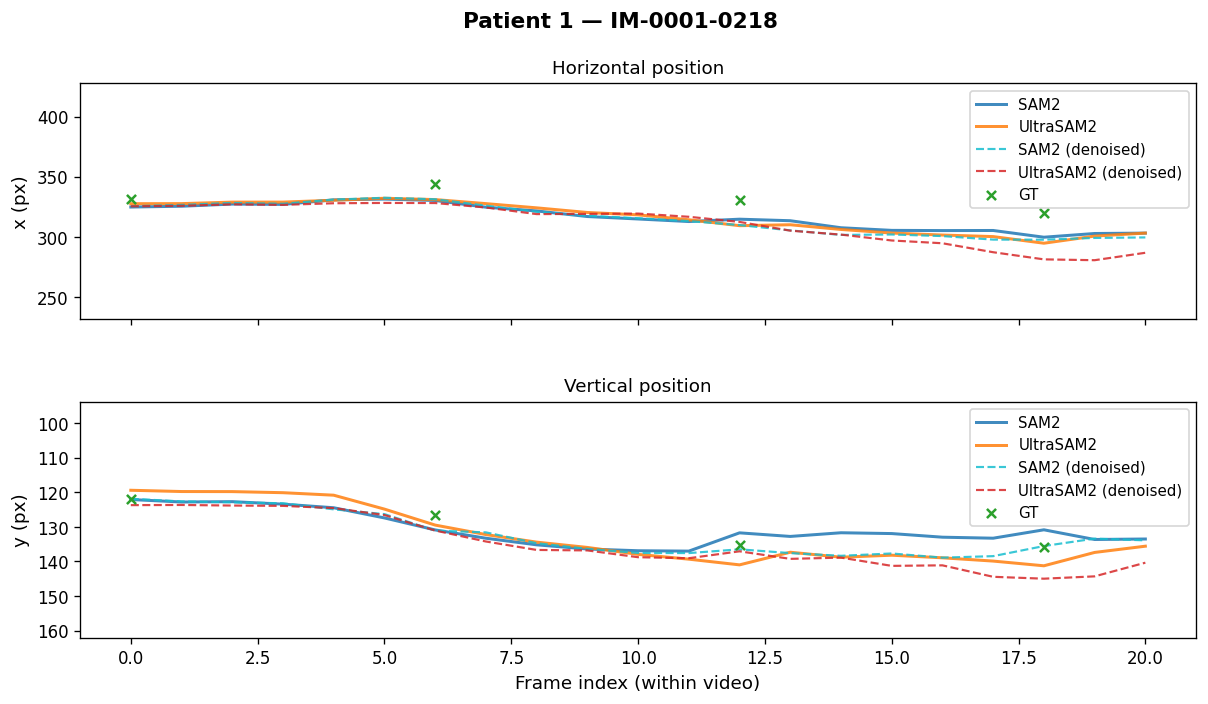

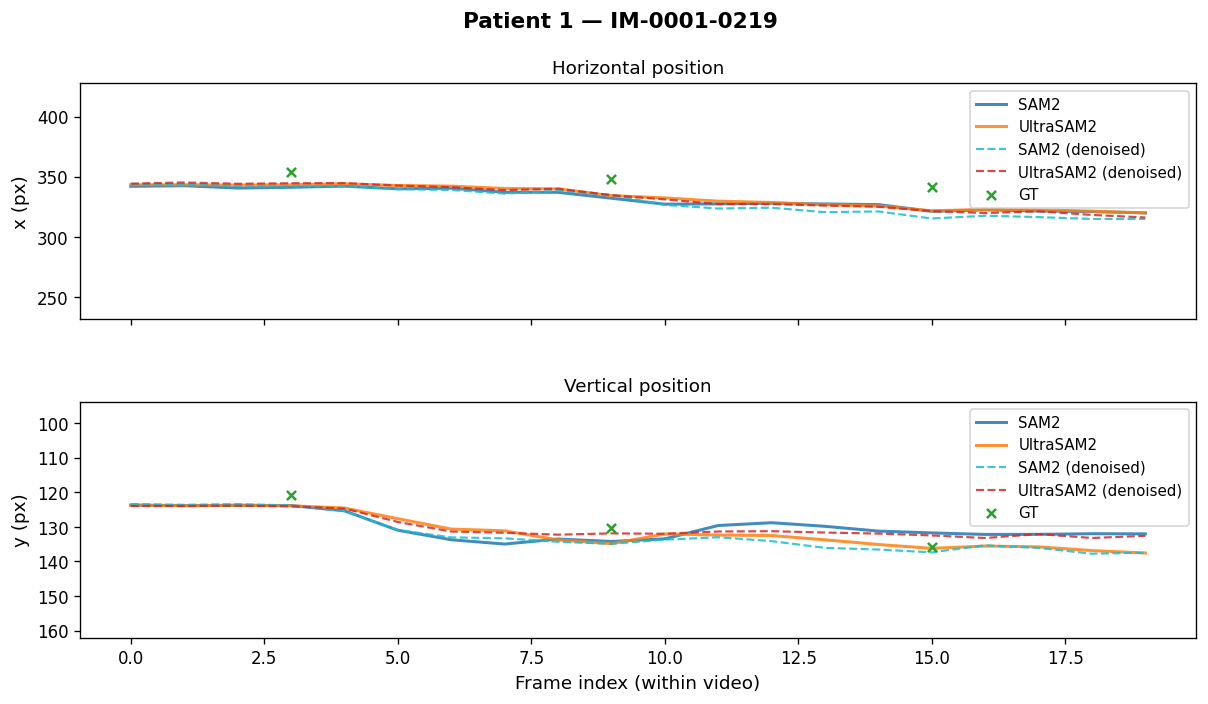

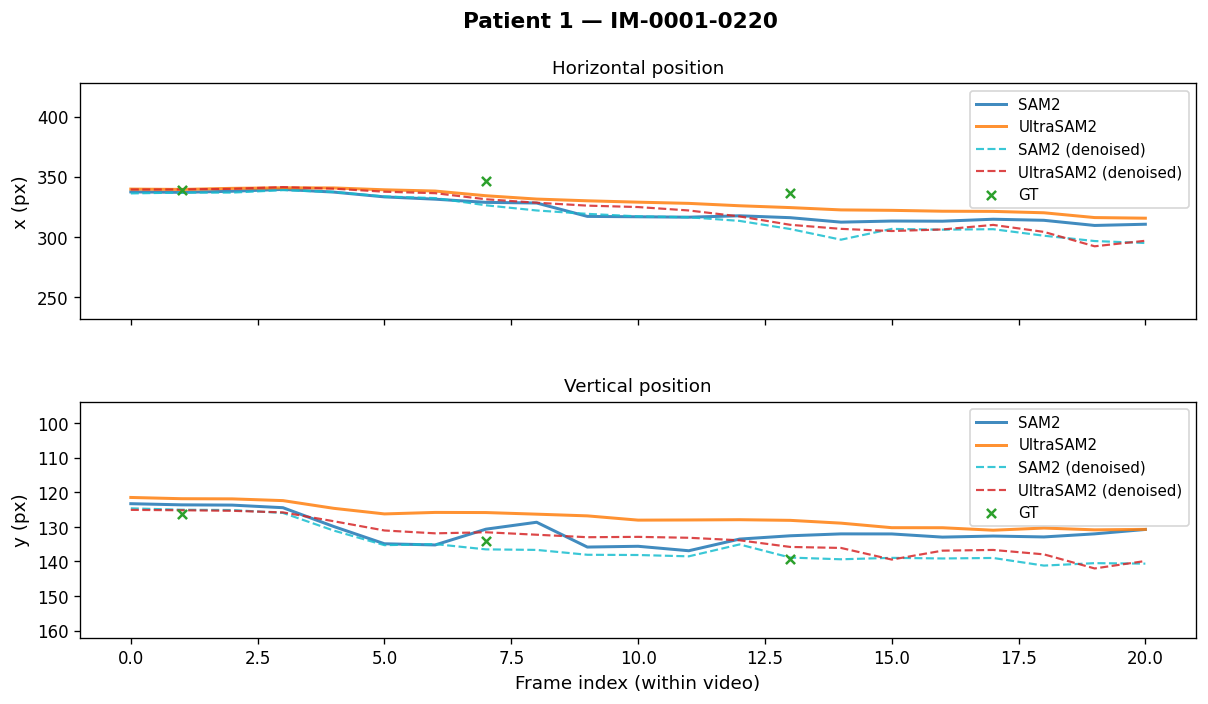

In [142]:
# ── Patient 1 — Almeida ───────────────────────────────────────────────────────
plot_patient_videos("Almeida")

Borges: cx=[273,351] cy=[128,162]
  axis window: x=[234,390]  y=[112,179]


C:\Users\João\AppData\Local\Temp\ipykernel_25428\1639915513.py:69: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.93])


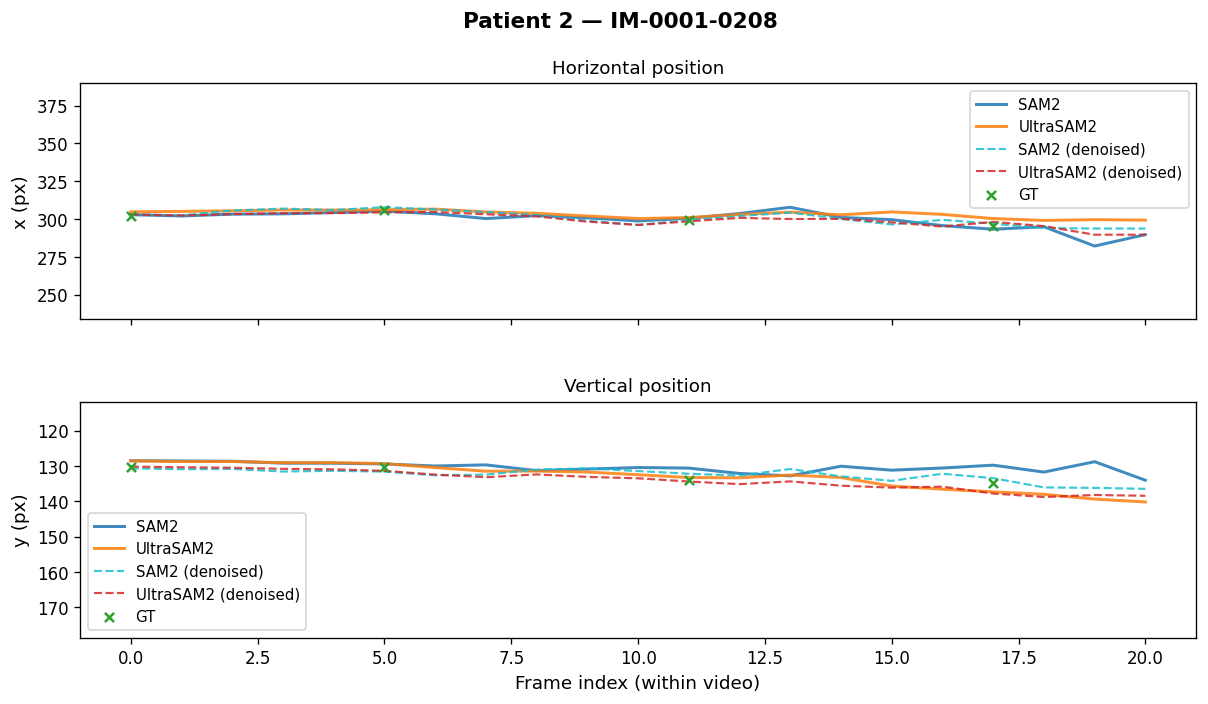

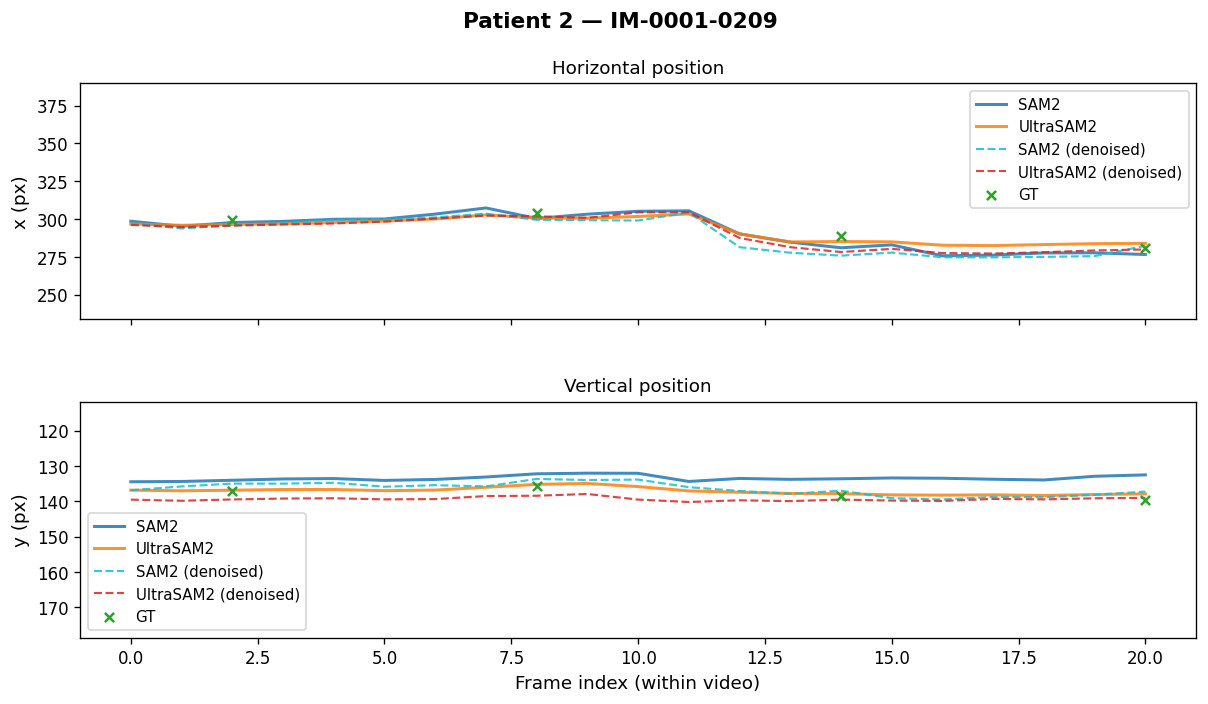

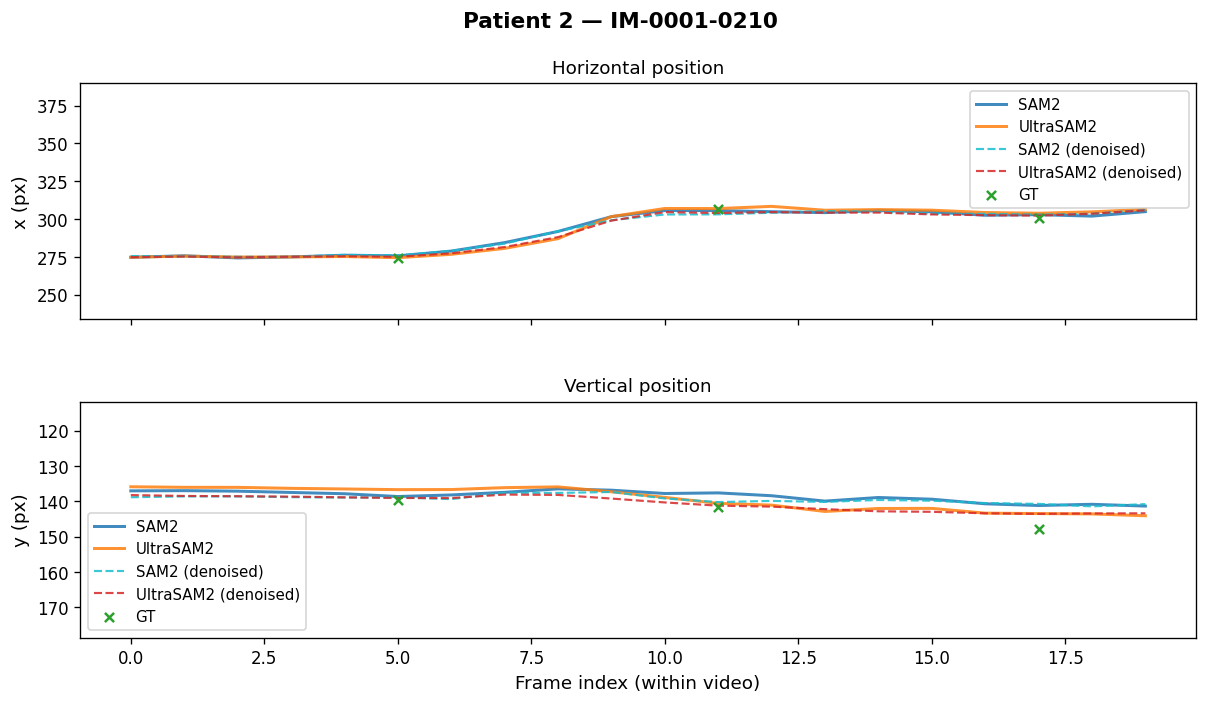

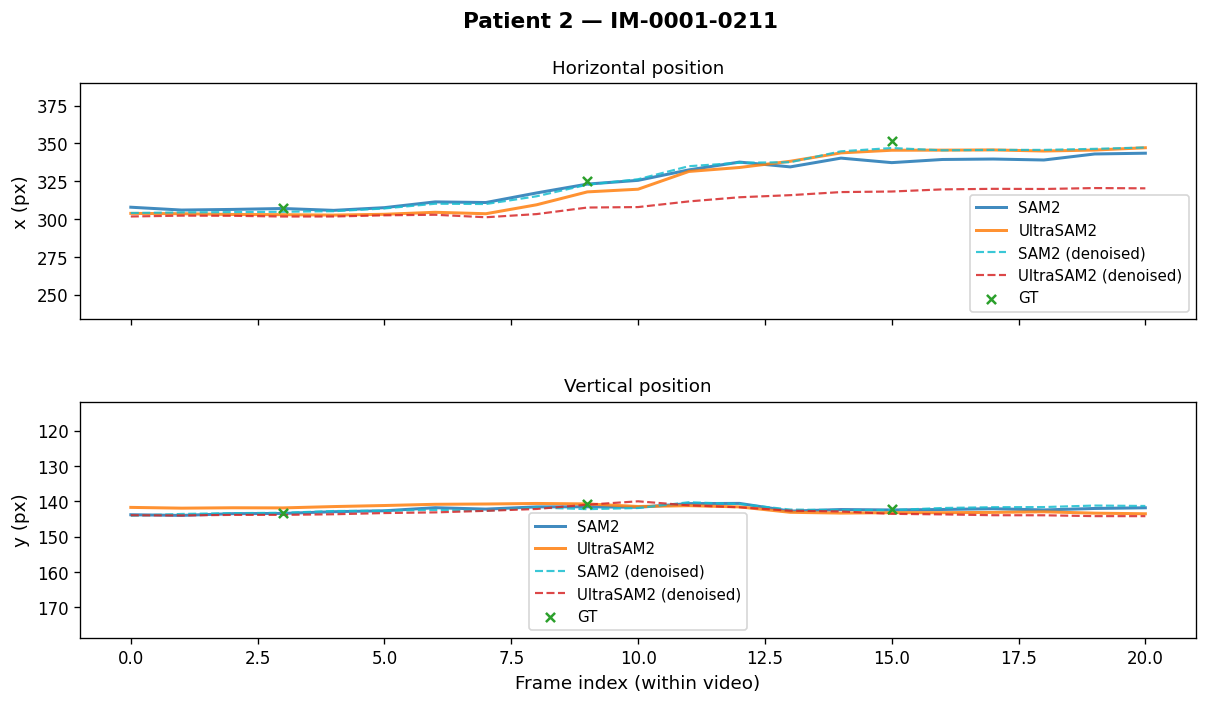

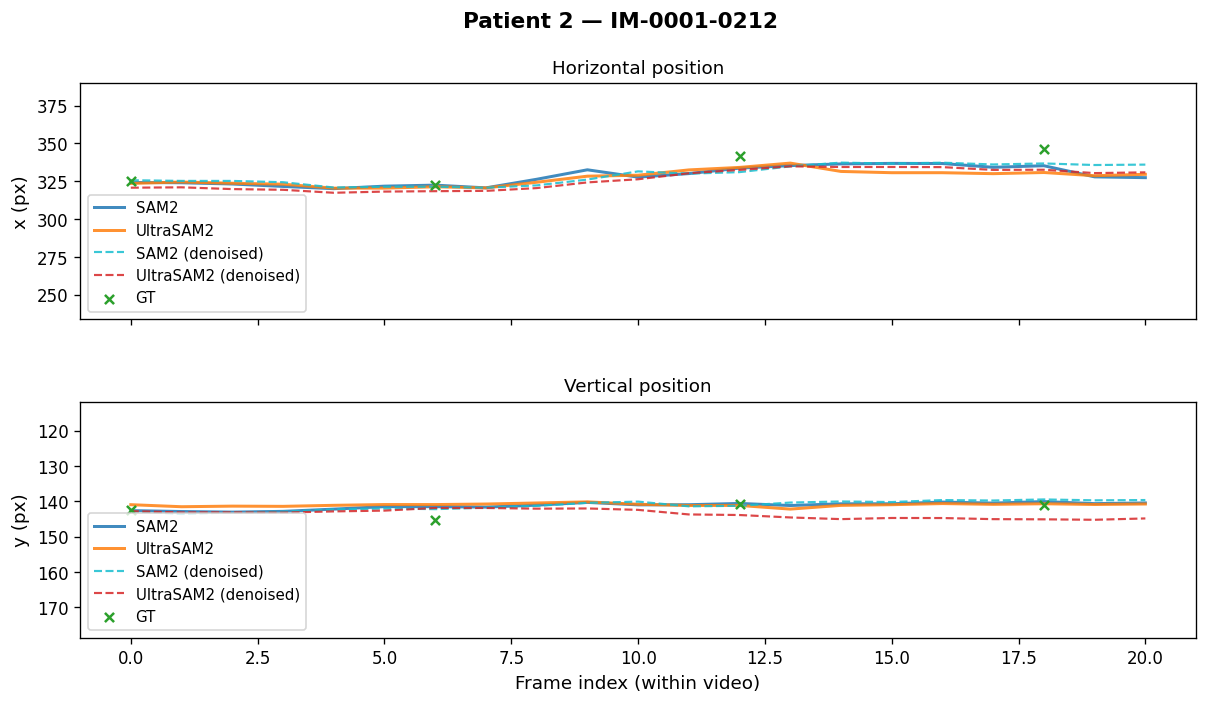

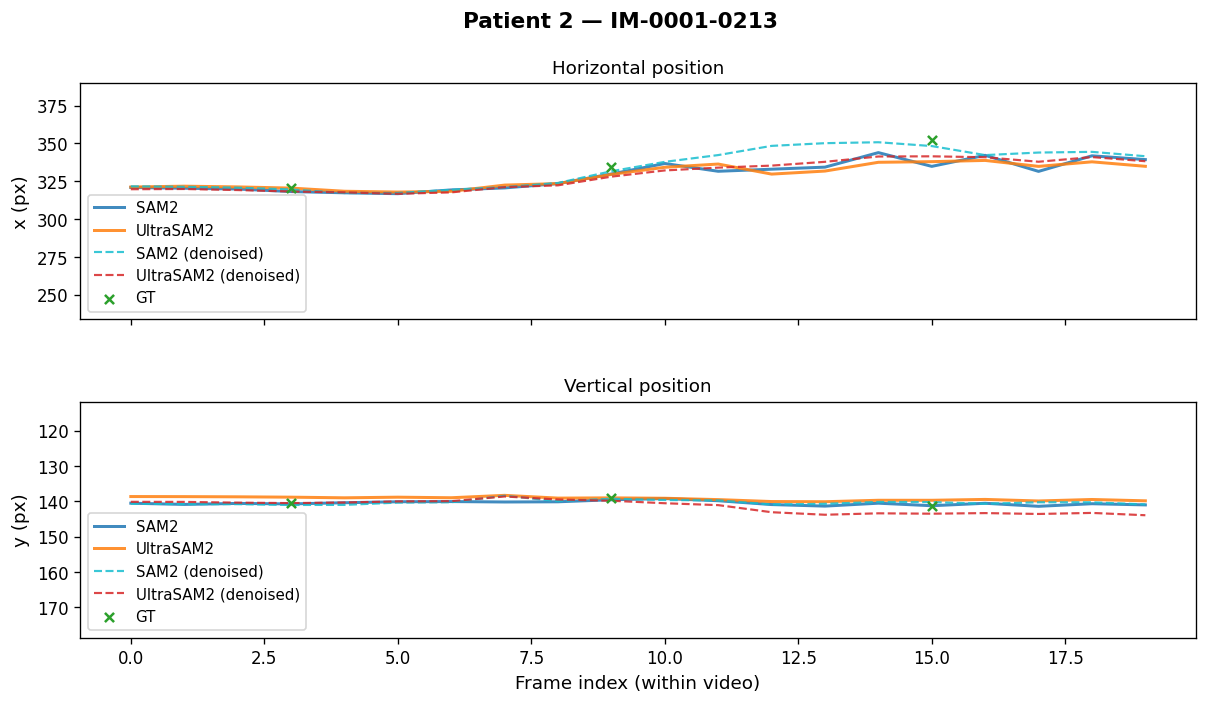

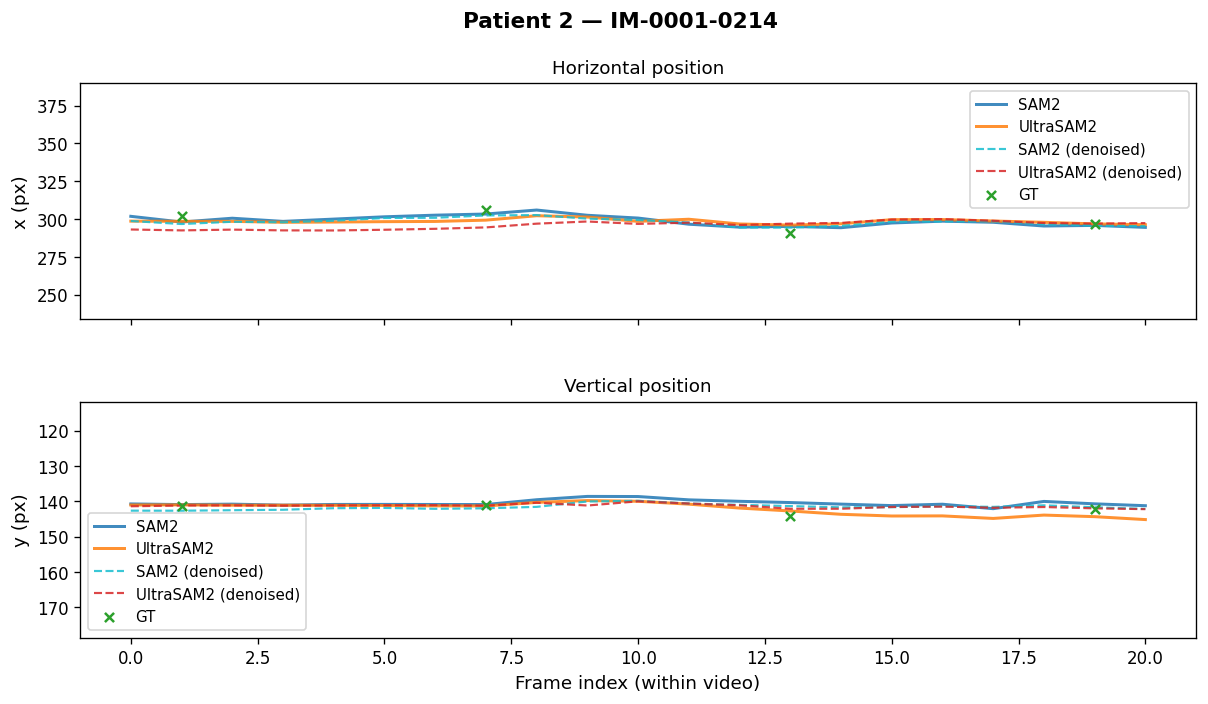

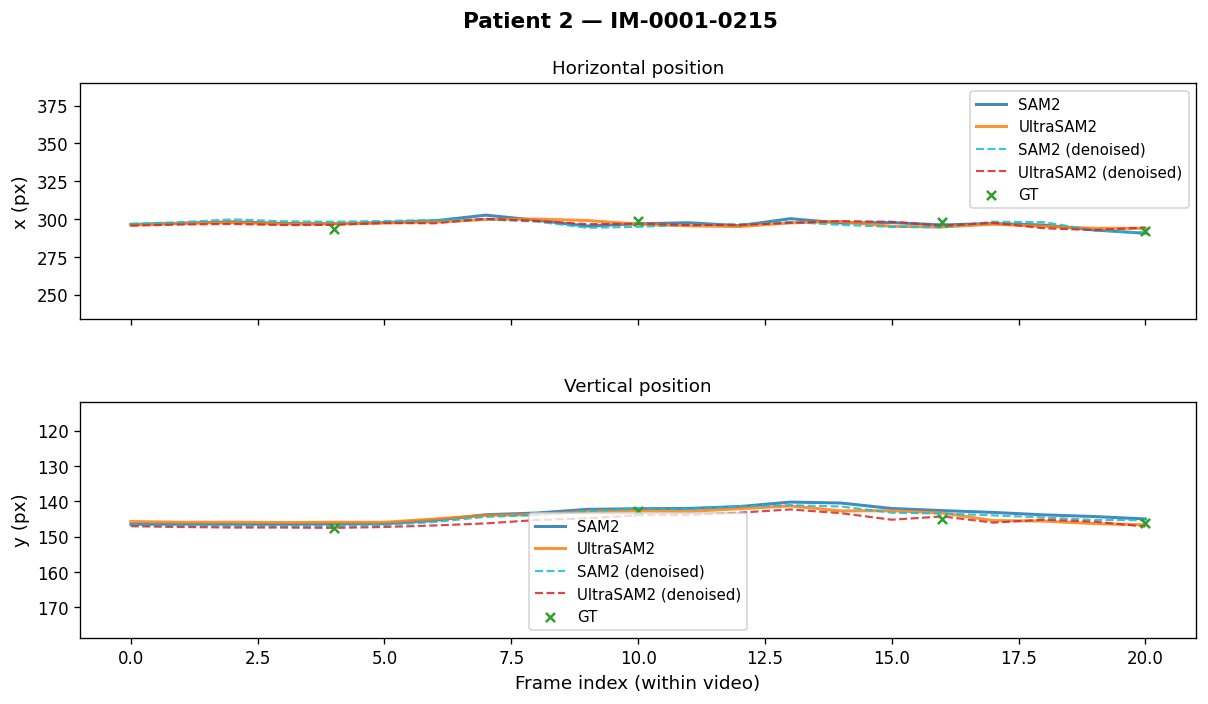

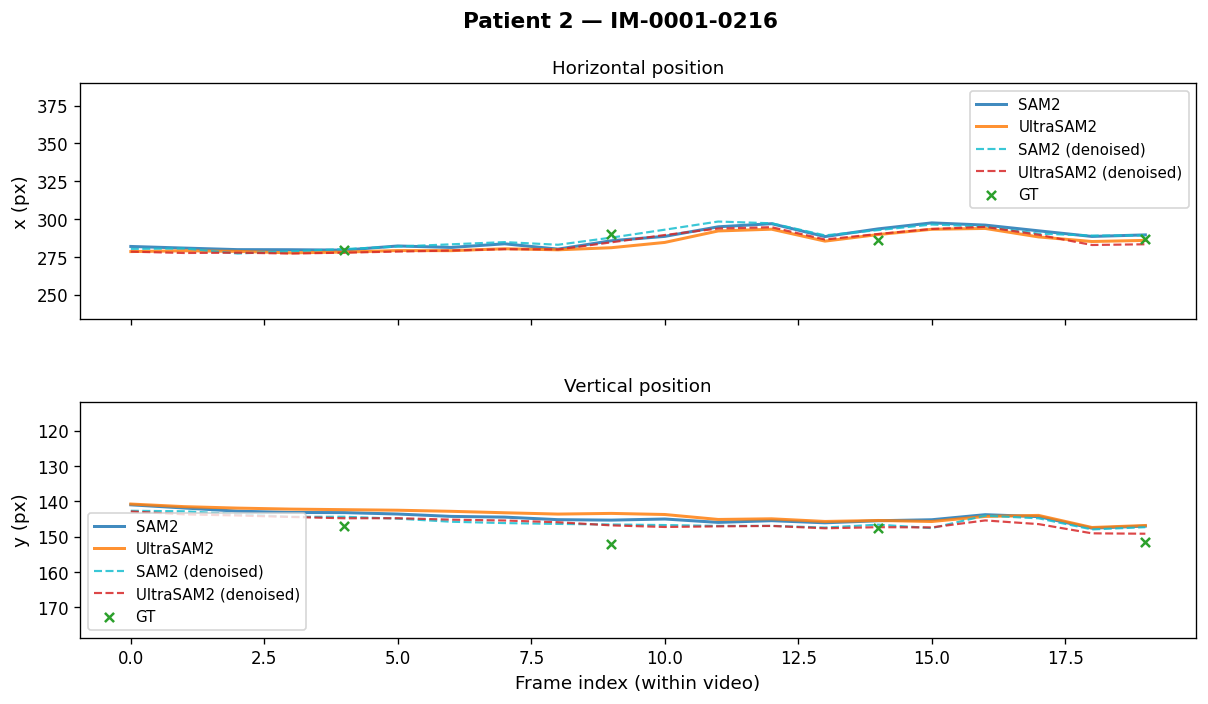

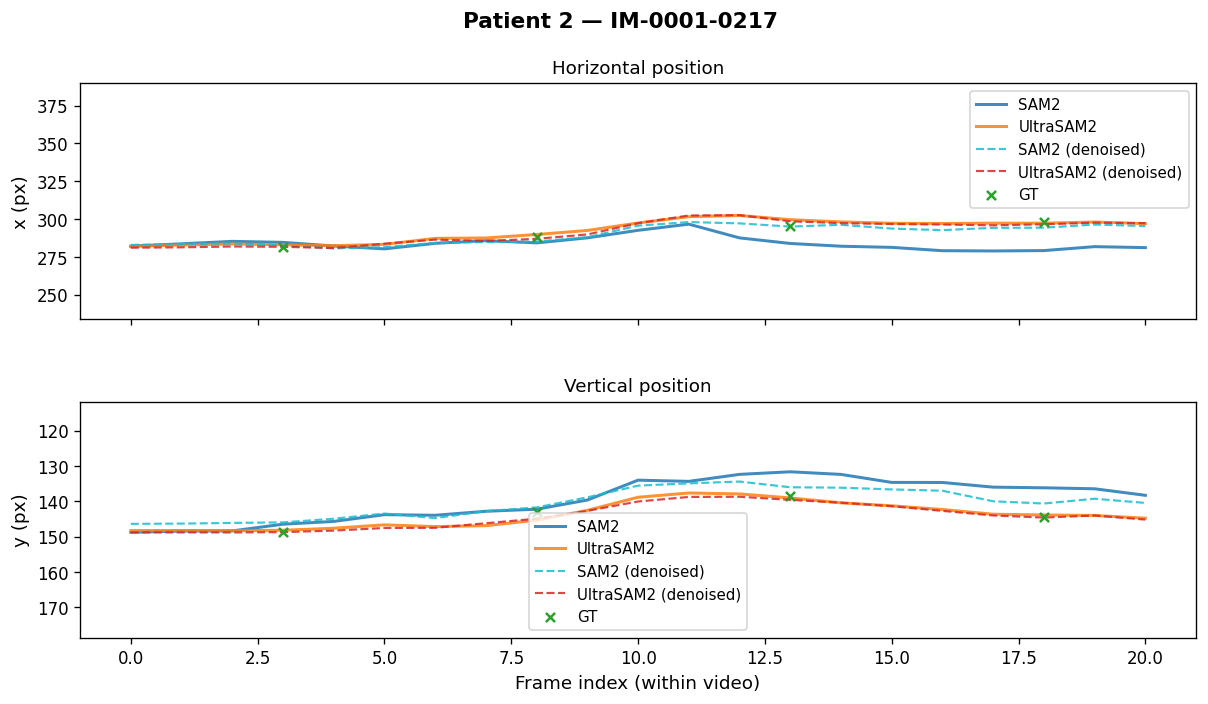

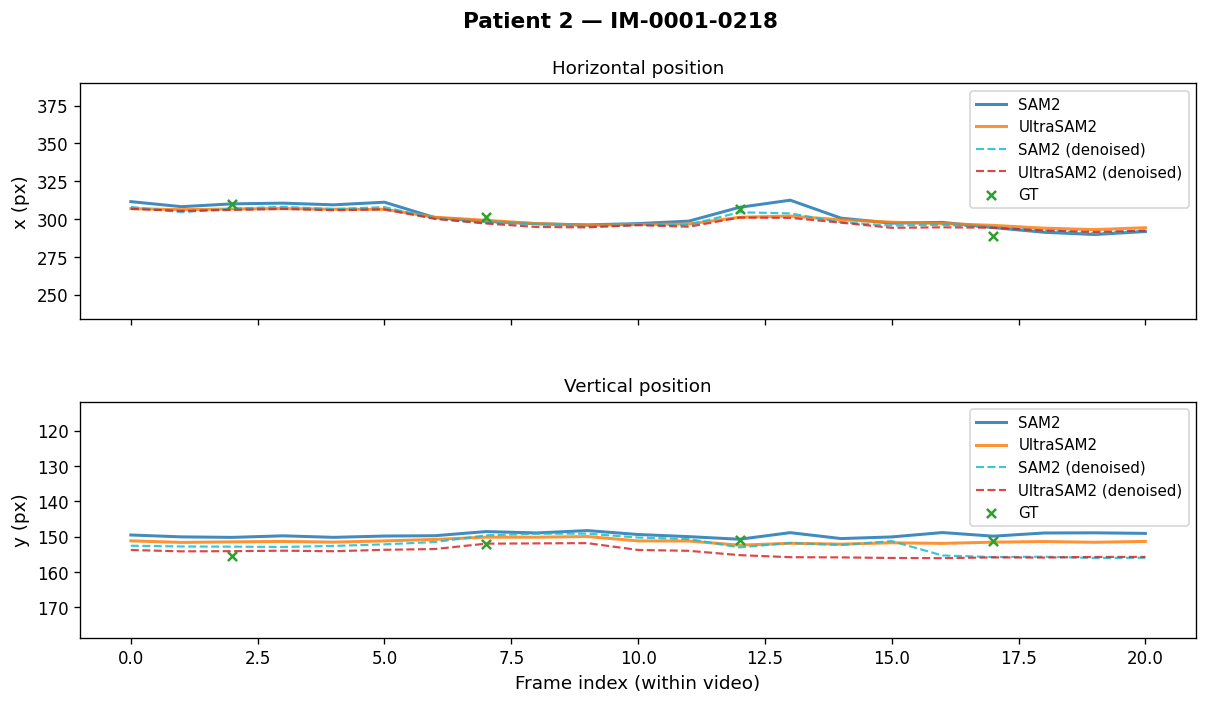

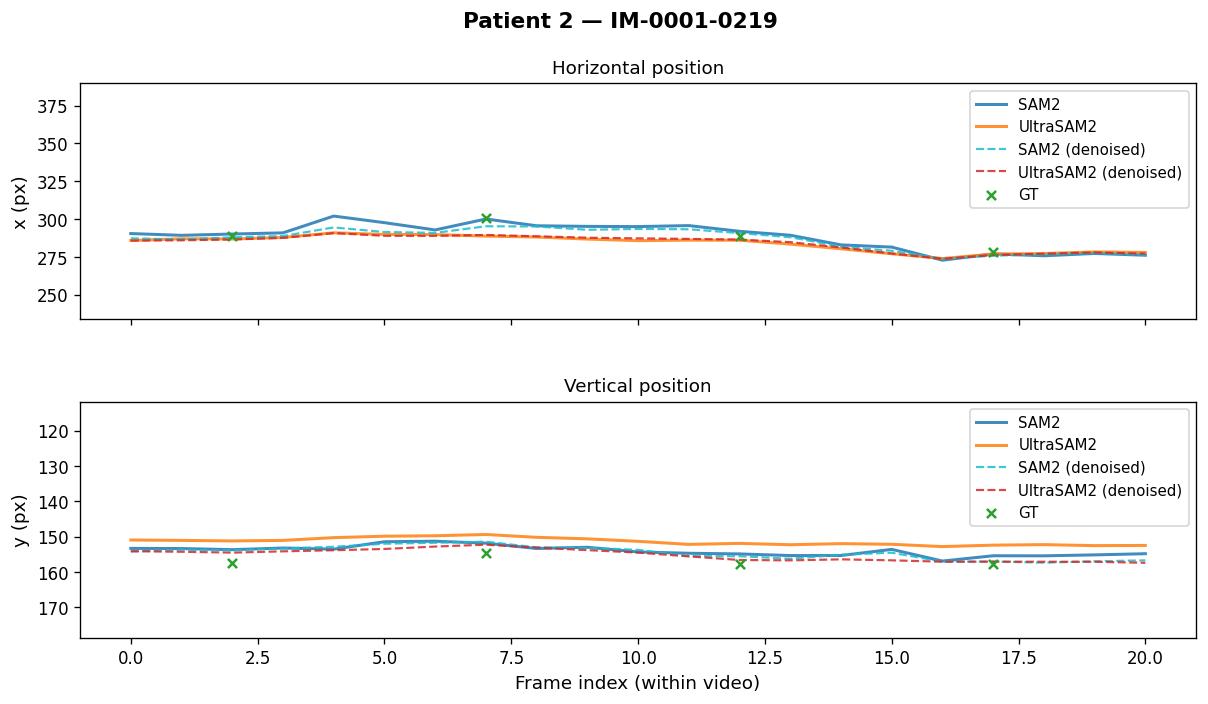

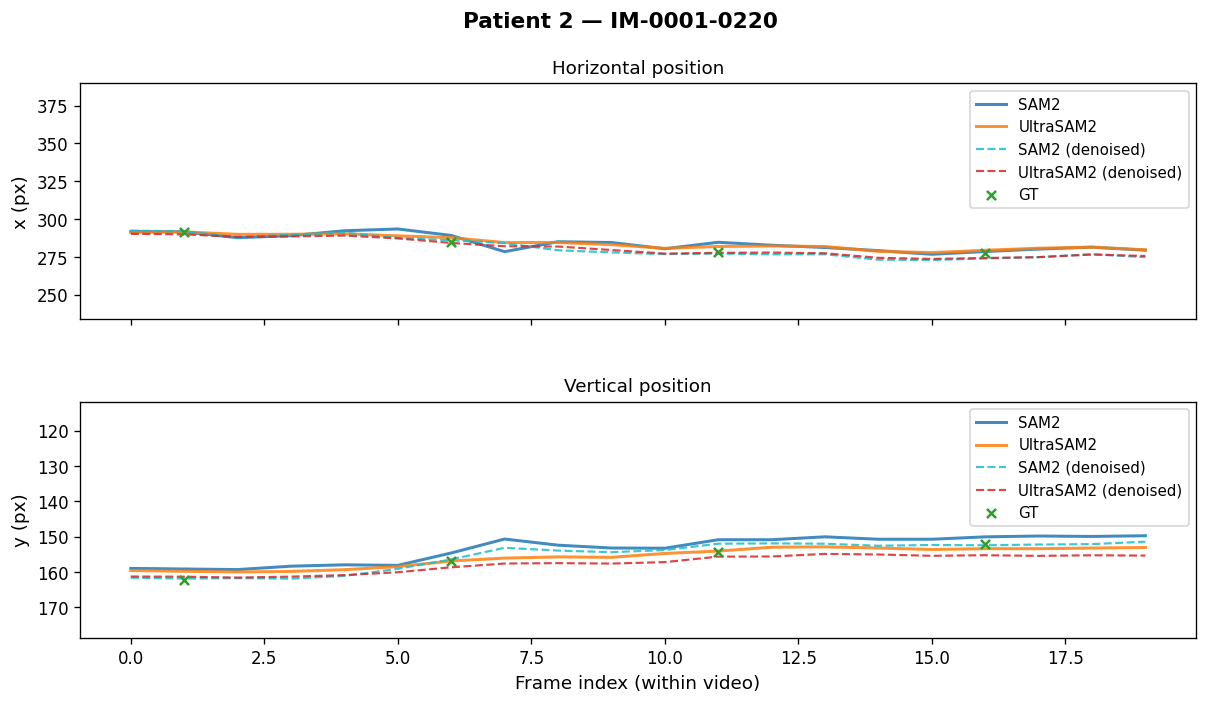

In [143]:
# ── Patient 2 — Borges ────────────────────────────────────────────────────────
plot_patient_videos("Borges")

Brito: cx=[227,322] cy=[148,186]
  axis window: x=[179,370]  y=[129,205]


C:\Users\João\AppData\Local\Temp\ipykernel_25428\1639915513.py:69: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.93])


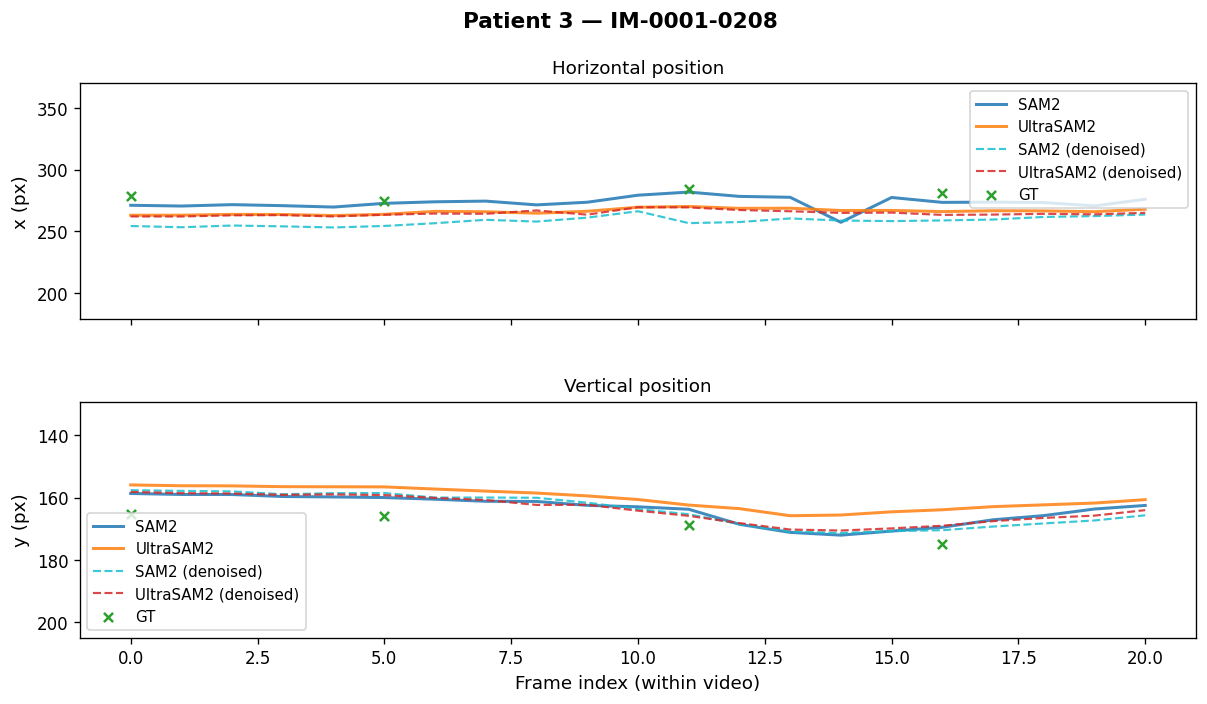

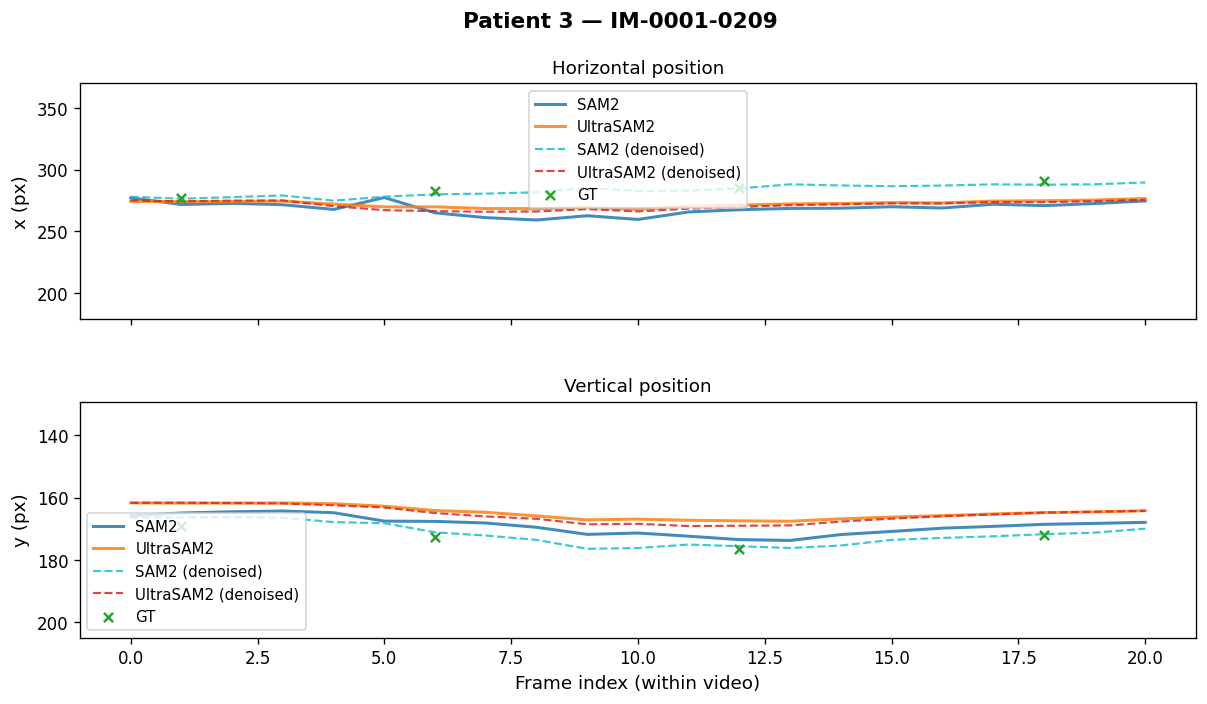

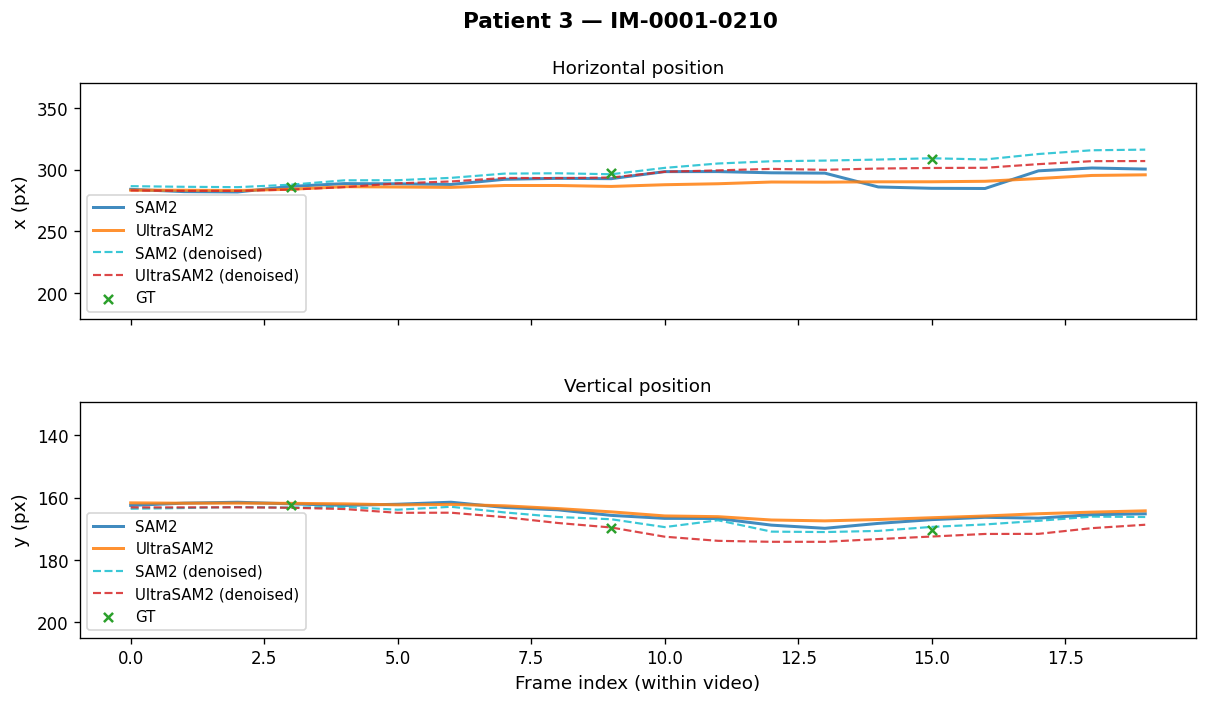

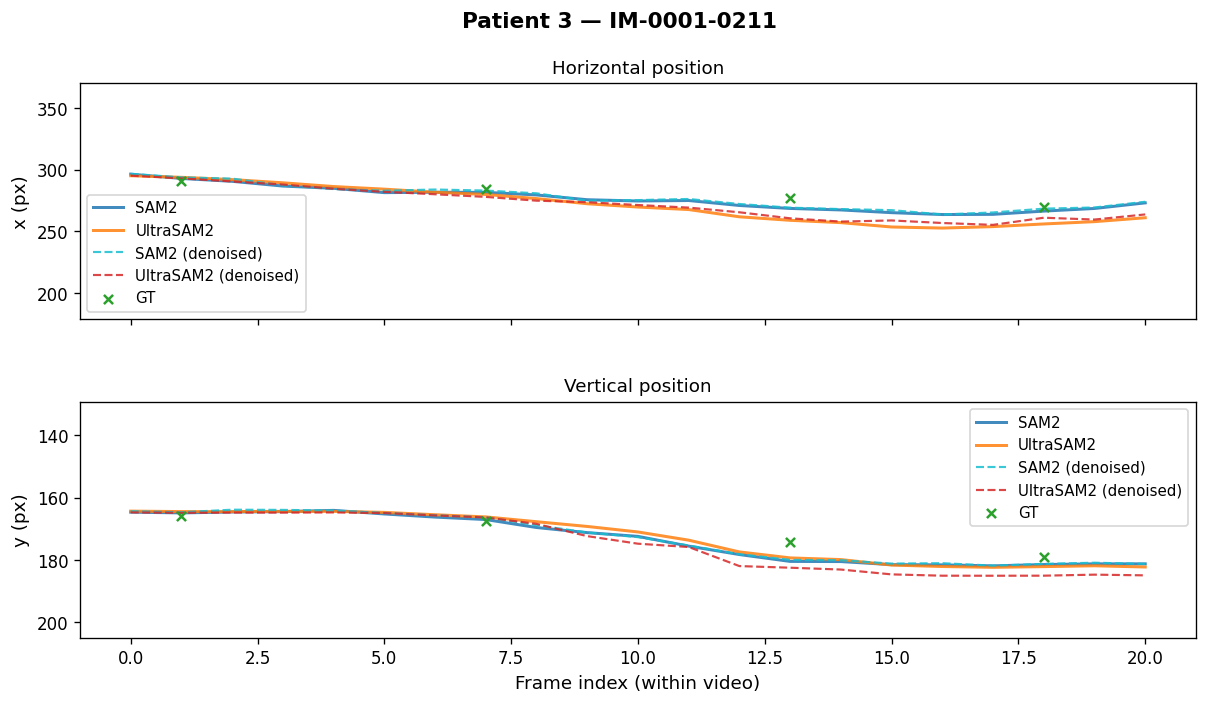

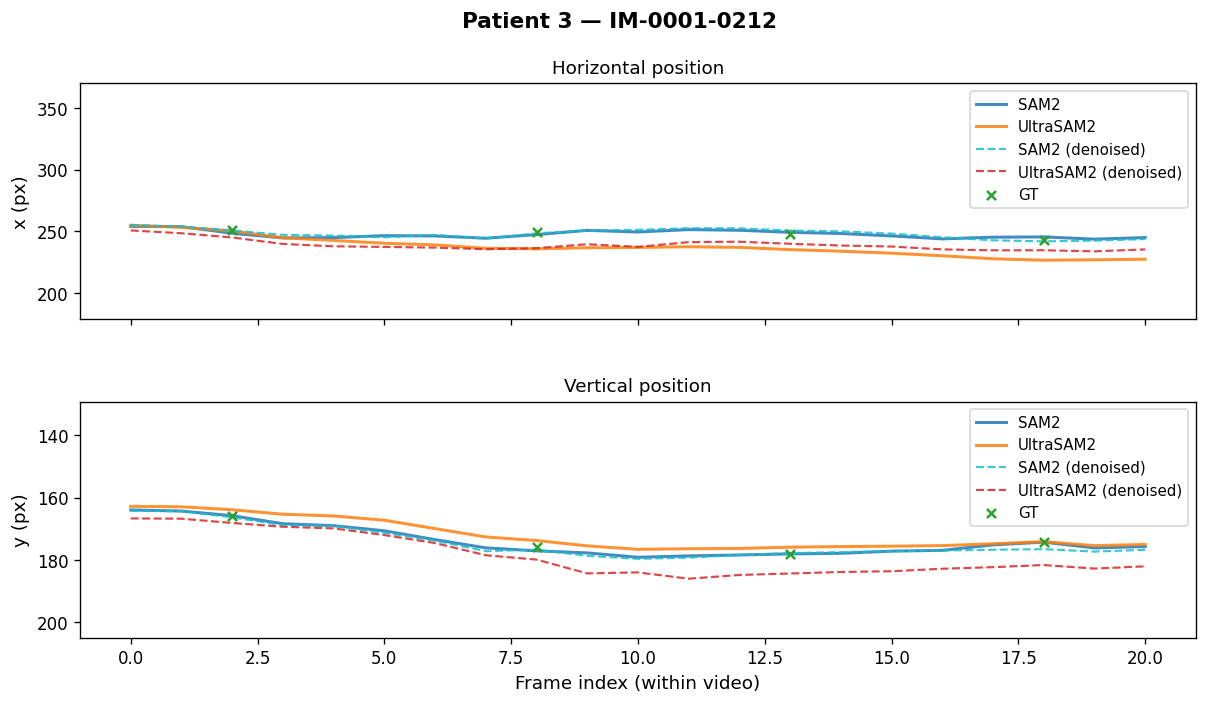

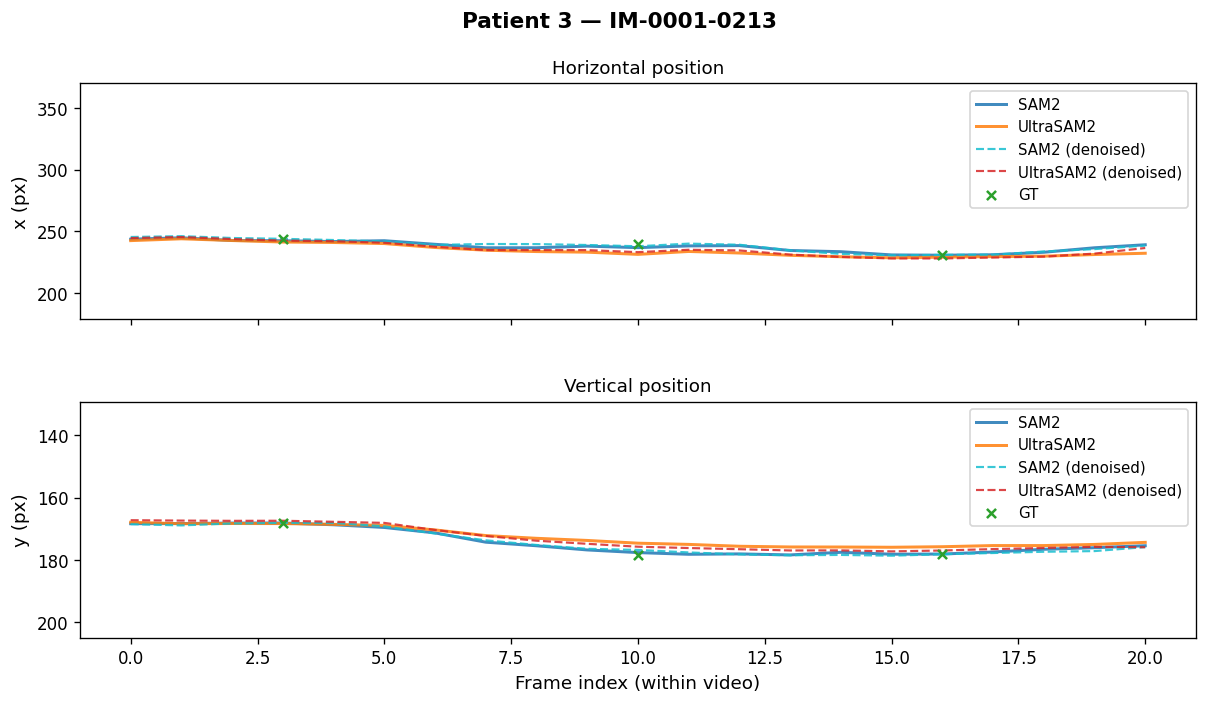

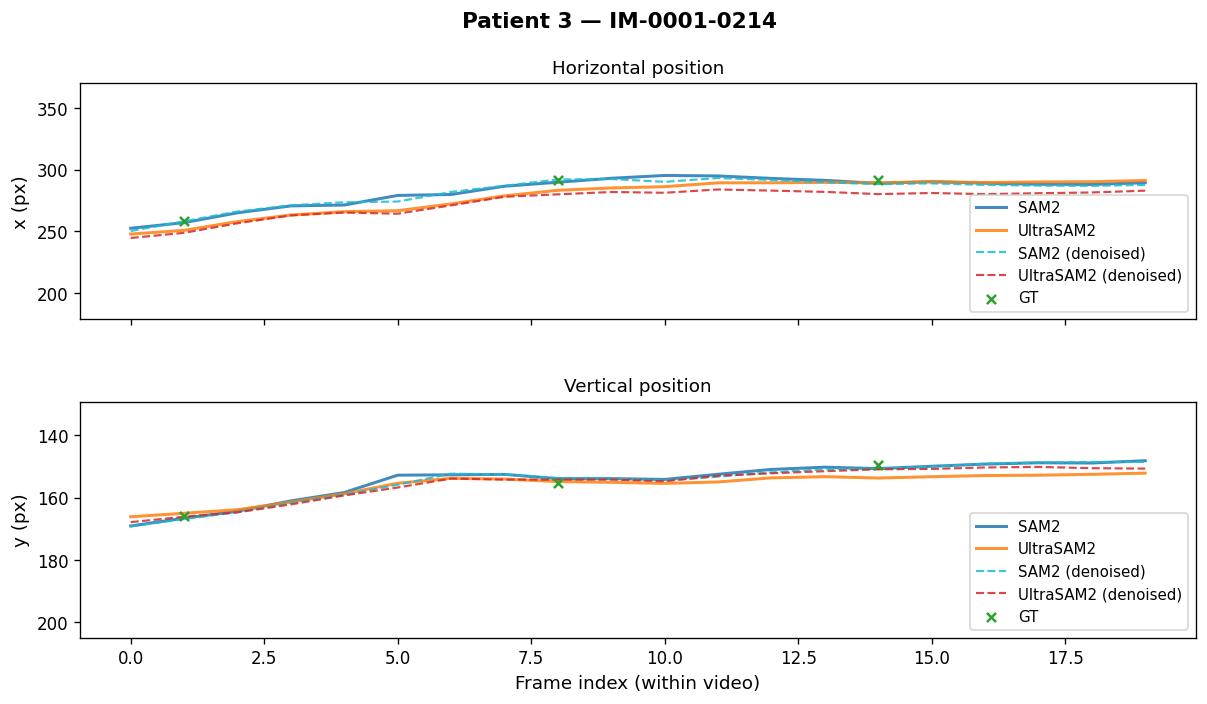

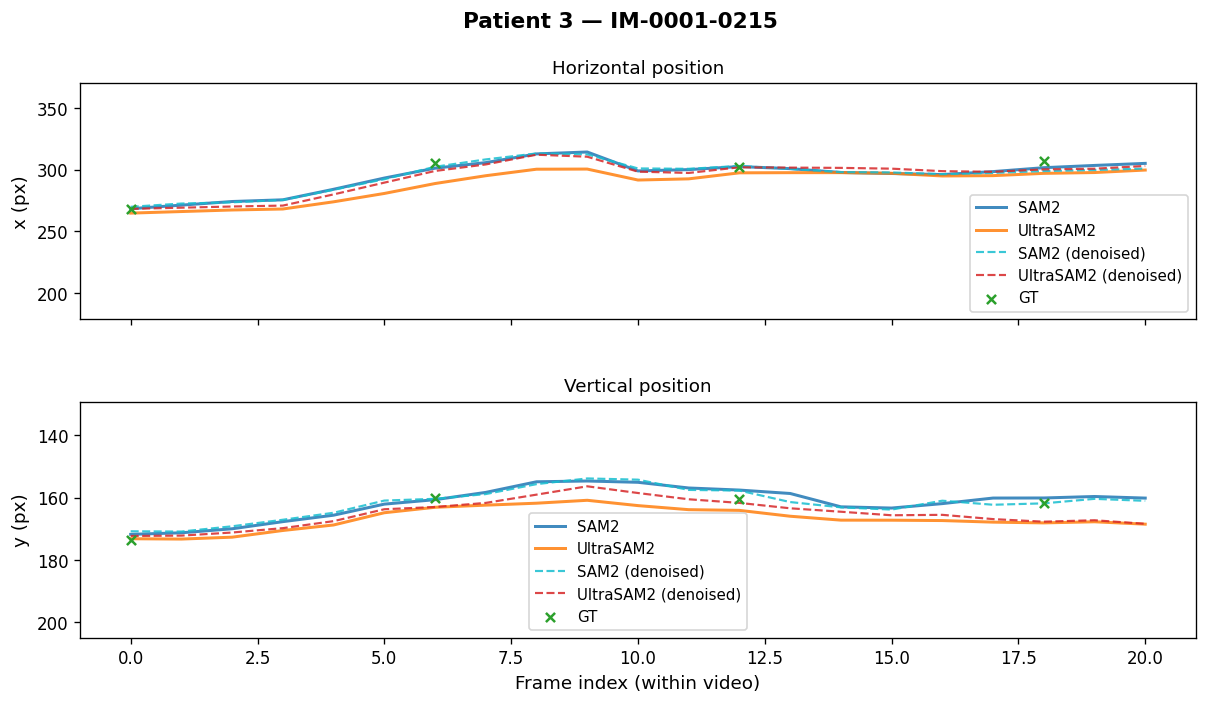

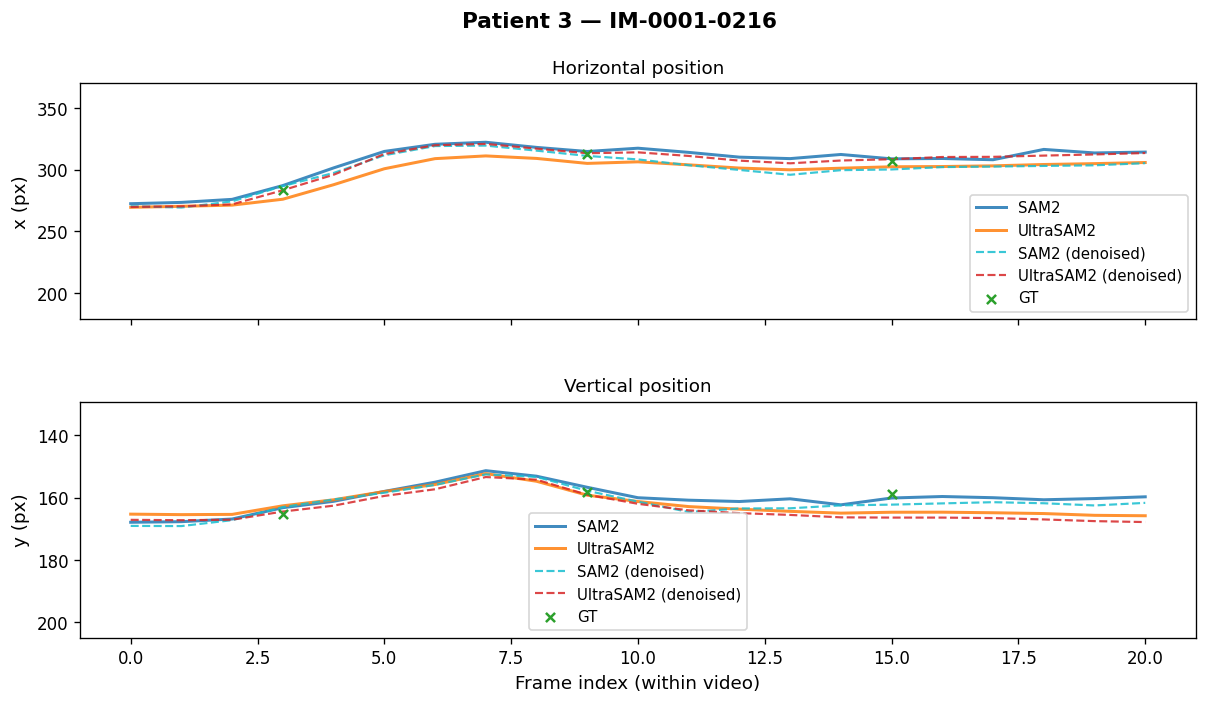

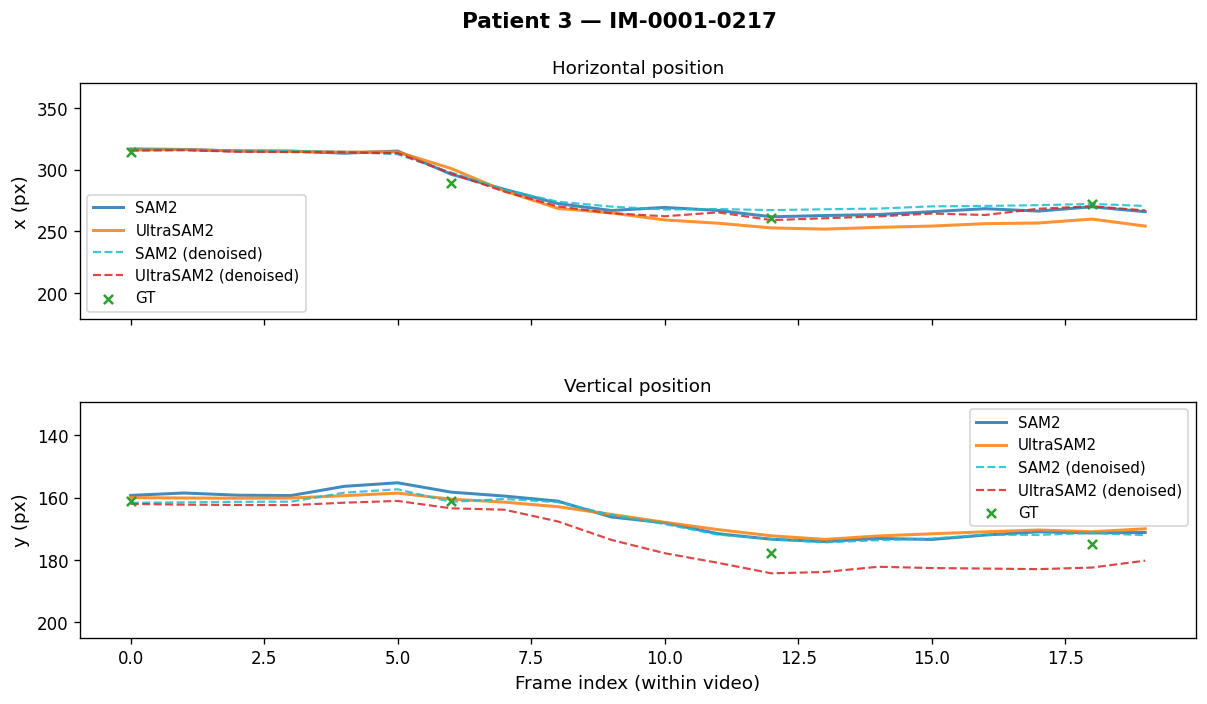

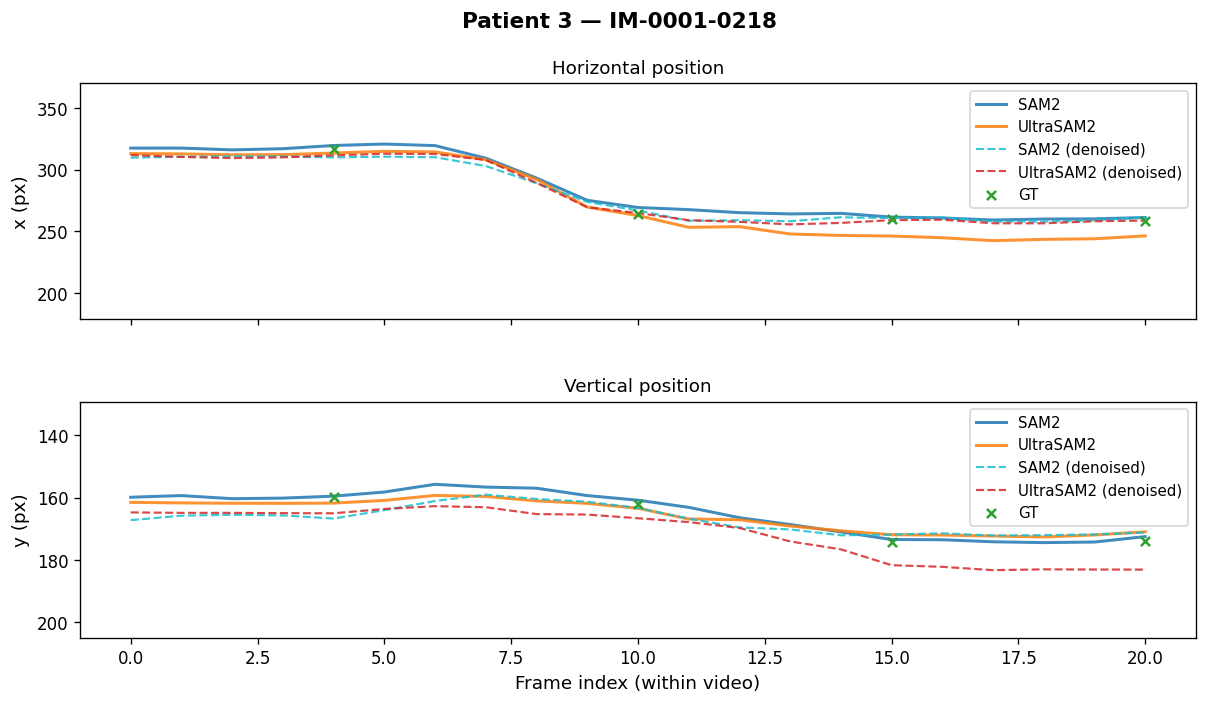

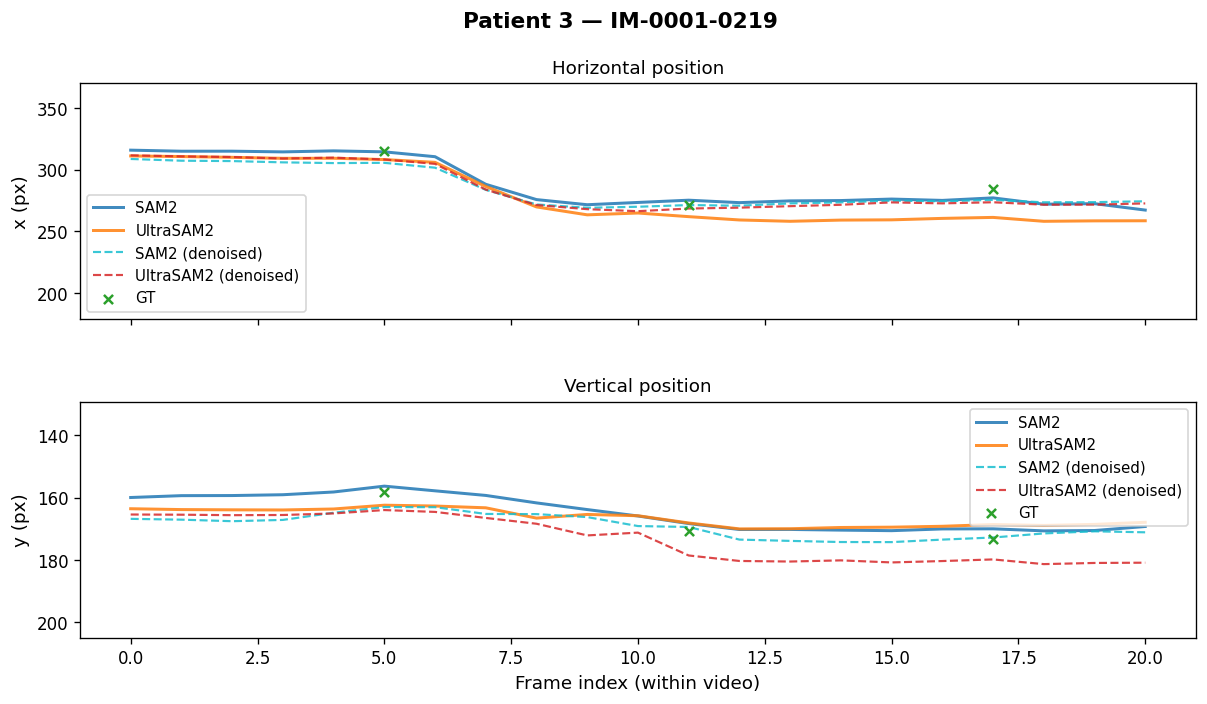

In [144]:
# ── Patient 3 — Brito ─────────────────────────────────────────────────────────
plot_patient_videos("Brito")